# Defra Air Quality Prediction Project

## a) All the imports

In [ ]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
import numpy as np 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.preprocessing import StandardScaler
from datetime import timedelta

import warnings
warnings.filterwarnings('ignore')
warnings.simplefilter('ignore', FutureWarning)

print("Successfully imported!")


## b) Loading combined raw data downloaded from defra

In [ ]:
df_raw = pd.read_csv("../data/combined/bloomsbury_2019_2023.csv")
print("\nData loading was successful!")
print(f"\nDataset Shape: {df_raw.shape}")
print(f"Number of records: {df_raw.shape[0]:,}")
print(f"Number of features: {df_raw.shape[1]}")


Data loading was successful!

Dataset Shape: (43824, 36)
Number of records: 43,824
Number of features: 36


### b.1)Show first and last 10 rows

In [ ]:


# Display basic information about the dataset
print(f"First 10 rows of the dataset:\n{df_raw.head(10)}\n")
print("==================================================================================")
print(f"Last 10 rows of the dataset:\n{df_raw.tail(10)}\n ")
print("==================================================================================")


First 10 rows of the dataset:
         Date   time  PM<sub>10</sub> particulate matter (Hourly measured)  \
0  01-01-2019  01:00                                                NaN      
1  01-01-2019  02:00                                                NaN      
2  01-01-2019  03:00                                                NaN      
3  01-01-2019  04:00                                                NaN      
4  01-01-2019  05:00                                                NaN      
5  01-01-2019  06:00                                                NaN      
6  01-01-2019  07:00                                                NaN      
7  01-01-2019  08:00                                                NaN      
8  01-01-2019  09:00                                                NaN      
9  01-01-2019  10:00                                                NaN      

  status unit  Nitric oxide status.1 unit.1  Nitrogen dioxide status.2  ...  \
0    NaN  NaN       9.50224     

In [ ]:
print("Data Types:")
print("="*60)
print(df_raw.dtypes)

Data Types:
Date                                                      object
time                                                      object
PM<sub>10</sub> particulate matter (Hourly measured)     float64
status                                                    object
unit                                                      object
Nitric oxide                                             float64
status.1                                                  object
unit.1                                                    object
Nitrogen dioxide                                         float64
status.2                                                  object
unit.2                                                    object
Nitrogen oxides as nitrogen dioxide                      float64
status.3                                                  object
unit.3                                                    object
Non-volatile PM<sub>10</sub> (Hourly measured)           float64
status.4     

### b.2) Inspect the columns

In [ ]:
print("Column Names:")
print("============================================================")
df_raw.columns.tolist()

Column Names:


['Date',
 'time',
 'PM<sub>10</sub> particulate matter (Hourly measured)',
 'status',
 'unit',
 'Nitric oxide',
 'status.1',
 'unit.1',
 'Nitrogen dioxide',
 'status.2',
 'unit.2',
 'Nitrogen oxides as nitrogen dioxide',
 'status.3',
 'unit.3',
 'Non-volatile PM<sub>10</sub> (Hourly measured)',
 'status.4',
 'unit.4',
 'Non-volatile PM<sub>2.5</sub> (Hourly measured)',
 'status.5',
 'unit.5',
 'Ozone',
 'status.6',
 'unit.6',
 'PM<sub>2.5</sub> particulate matter (Hourly measured)',
 'status.7',
 'unit.7',
 'Sulphur dioxide',
 'status.8',
 'unit.8',
 'Volatile PM<sub>10</sub> (Hourly measured)',
 'status.9',
 'unit.9',
 'Volatile PM<sub>2.5</sub> (Hourly measured)',
 'status.10',
 'unit.10',
 'year']

## c) Initial Data Inspection

### c.1) Data Details

In [ ]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43824 entries, 0 to 43823
Data columns (total 36 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   Date                                                   43824 non-null  object 
 1   time                                                   43824 non-null  object 
 2   PM<sub>10</sub> particulate matter (Hourly measured)   41334 non-null  float64
 3   status                                                 41334 non-null  object 
 4   unit                                                   41334 non-null  object 
 5   Nitric oxide                                           40269 non-null  float64
 6   status.1                                               40269 non-null  object 
 7   unit.1                                                 40269 non-null  object 
 8   Nitrogen dioxide                              

### c.2) description

In [ ]:
print("Descriptive analysis of raw data:")
df_raw.describe()

Descriptive analysis of raw data:


,PM<sub>10</sub> particulate matter (Hourly measured),Nitric oxide,Nitrogen dioxide,Nitrogen oxides as nitrogen dioxide,Non-volatile PM<sub>10</sub> (Hourly measured),Non-volatile PM<sub>2.5</sub> (Hourly measured),Ozone,PM<sub>2.5</sub> particulate matter (Hourly measured),Sulphur dioxide,Volatile PM<sub>10</sub> (Hourly measured),Volatile PM<sub>2.5</sub> (Hourly measured),year
count,41334.000000,40269.000000,40269.000000,40269.000000,9037.000000,9590.000000,41814.000000,33205.000000,36709.000000,9037.000000,9590.000000,43824.000000
mean,16.002474,6.568707,27.258535,37.330411,13.935189,9.077091,44.189867,9.200208,1.138816,3.454731,3.230031,2020.999452
std,10.705461,13.581318,17.100054,34.473298,9.614273,7.329728,23.116813,8.217367,1.174002,3.570716,3.191411,1.414036
min,-3.768000,-0.031180,0.462560,1.234950,-2.200000,-3.600000,-0.648600,-4.000000,-0.330410,-10.000000,-6.400000,2019.000000
25%,9.500000,0.961820,14.355370,16.476730,8.100000,4.700000,28.388830,4.500000,0.607430,1.300000,1.200000,2020.000000
50%,13.527000,2.226380,22.981060,27.137990,11.500000,7.100000,44.404330,6.900000,0.932930,2.700000,2.500000,2021.000000
75%,19.375000,6.125100,36.235550,45.551870,16.900000,10.900000,58.923040,10.991000,1.387530,4.600000,4.400000,2022.000000
max,194.125000,289.385360,122.209670,549.810930,84.200000,66.300000,187.745480,154.000000,98.181240,34.000000,30.600000,2023.000000


### c.3) missing values

In [ ]:
# Check for missing values
missing_values = df_raw.isnull().sum()
missing_percentage = ((df_raw.isnull().sum() / len(df_raw)) * 100).map(lambda x: f"{x:.2f}%")

missing_df = pd.DataFrame({
    'Missing Count': missing_values,
    'Percentage': missing_percentage
})

print("Missing Values Summary:\n")
print(missing_df[missing_df['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False))

Missing Values Summary:

                                                    Missing Count Percentage
Non-volatile PM<sub>10</sub> (Hourly measured)              34787     79.38%
unit.9                                                      34787     79.38%
status.9                                                    34787     79.38%
Volatile PM<sub>10</sub> (Hourly measured)                  34787     79.38%
Volatile PM<sub>2.5</sub> (Hourly measured)                 34234     78.12%
status.10                                                   34234     78.12%
Non-volatile PM<sub>2.5</sub> (Hourly measured)             34234     78.12%
unit.10                                                     34234     78.12%
status.8                                                    30546     69.70%
unit.8                                                      30546     69.70%
unit.7                                                      27551     62.87%
status.7                                           

### c.4) Duplicate timestamps

In [ ]:
#counting duplicate timestamps
duplicate_time = df_raw["time"].duplicated().sum()
duplicate_date = df_raw["Date"].duplicated().sum()

print(f"Number of Duplicate Date:  {duplicate_date}\nNumber of Duplicate Time: {duplicate_time}")

Number of Duplicate Date:  41998
Number of Duplicate Time: 43800


### d) Data Cleaning

### d.1) Remove html tags

In [ ]:
df_raw.columns = (df_raw.columns.str.strip().str.replace("<sub>", "", regex=False).str.replace("</sub>", "", regex=False))
print("List of column after removing HTML tags:")
df_raw.columns.tolist()

List of column after removing HTML tags:


['Date',
 'time',
 'PM10 particulate matter (Hourly measured)',
 'status',
 'unit',
 'Nitric oxide',
 'status.1',
 'unit.1',
 'Nitrogen dioxide',
 'status.2',
 'unit.2',
 'Nitrogen oxides as nitrogen dioxide',
 'status.3',
 'unit.3',
 'Non-volatile PM10 (Hourly measured)',
 'status.4',
 'unit.4',
 'Non-volatile PM2.5 (Hourly measured)',
 'status.5',
 'unit.5',
 'Ozone',
 'status.6',
 'unit.6',
 'PM2.5 particulate matter (Hourly measured)',
 'status.7',
 'unit.7',
 'Sulphur dioxide',
 'status.8',
 'unit.8',
 'Volatile PM10 (Hourly measured)',
 'status.9',
 'unit.9',
 'Volatile PM2.5 (Hourly measured)',
 'status.10',
 'unit.10',
 'year']

### d.2) Convert date column to datetime 

In [ ]:
df_raw["datetime"] = pd.to_datetime(df_raw["Date"] + " " + df_raw["time"], dayfirst=True, errors="coerce")
df_raw = df_raw.drop(columns=["Date", "time"])

df_raw.columns

Index(['PM10 particulate matter (Hourly measured)', 'status', 'unit',
       'Nitric oxide', 'status.1', 'unit.1', 'Nitrogen dioxide', 'status.2',
       'unit.2', 'Nitrogen oxides as nitrogen dioxide', 'status.3', 'unit.3',
       'Non-volatile PM10 (Hourly measured)', 'status.4', 'unit.4',
       'Non-volatile PM2.5 (Hourly measured)', 'status.5', 'unit.5', 'Ozone',
       'status.6', 'unit.6', 'PM2.5 particulate matter (Hourly measured)',
       'status.7', 'unit.7', 'Sulphur dioxide', 'status.8', 'unit.8',
       'Volatile PM10 (Hourly measured)', 'status.9', 'unit.9',
       'Volatile PM2.5 (Hourly measured)', 'status.10', 'unit.10', 'year',
       'datetime'],
      dtype='object')

### d.3) Converting pollutants columns to numeric

In [ ]:
# coverting all columns numeric except datetime and year
for col in df_raw.columns:
    if col not in ["datetime", "year"]:
        df_raw[col] = pd.to_numeric(df_raw[col], errors="coerce")


### d.4) Dropping units and statuses column

In [ ]:
df_raw = df_raw.dropna(axis=1, how="all")
df_raw.head()

,PM10 particulate matter (Hourly measured),Nitric oxide,Nitrogen dioxide,Nitrogen oxides as nitrogen dioxide,Non-volatile PM10 (Hourly measured),Non-volatile PM2.5 (Hourly measured),Ozone,PM2.5 particulate matter (Hourly measured),Sulphur dioxide,Volatile PM10 (Hourly measured),Volatile PM2.5 (Hourly measured),year,datetime
0,NaN,9.50224,47.04939,61.61929,NaN,8.8,35.32389,11.0,0.90306,NaN,2.2,2019,2019-01-01 01:00:00
1,NaN,7.38007,43.39999,54.71595,NaN,11.4,35.45694,12.4,1.08368,NaN,1.0,2019,2019-01-01 02:00:00
2,NaN,8.33030,39.07622,51.84917,NaN,3.8,40.81207,2.8,1.15141,NaN,-1.0,2019,2019-01-01 03:00:00
3,NaN,3.29411,22.43064,27.48154,NaN,4.7,49.64304,5.7,0.94822,NaN,1.0,2019,2019-01-01 04:00:00
4,NaN,5.25791,36.02708,44.08909,NaN,3.5,38.61680,4.7,0.88049,NaN,1.2,2019,2019-01-01 05:00:00


### d.5) Sort by datetime

In [ ]:
df_raw = df_raw.sort_values("datetime").reset_index(drop=True)
df_raw.head()

,PM10 particulate matter (Hourly measured),Nitric oxide,Nitrogen dioxide,Nitrogen oxides as nitrogen dioxide,Non-volatile PM10 (Hourly measured),Non-volatile PM2.5 (Hourly measured),Ozone,PM2.5 particulate matter (Hourly measured),Sulphur dioxide,Volatile PM10 (Hourly measured),Volatile PM2.5 (Hourly measured),year,datetime
0,NaN,9.50224,47.04939,61.61929,NaN,8.8,35.32389,11.0,0.90306,NaN,2.2,2019,2019-01-01 01:00:00
1,NaN,7.38007,43.39999,54.71595,NaN,11.4,35.45694,12.4,1.08368,NaN,1.0,2019,2019-01-01 02:00:00
2,NaN,8.33030,39.07622,51.84917,NaN,3.8,40.81207,2.8,1.15141,NaN,-1.0,2019,2019-01-01 03:00:00
3,NaN,3.29411,22.43064,27.48154,NaN,4.7,49.64304,5.7,0.94822,NaN,1.0,2019,2019-01-01 04:00:00
4,NaN,5.25791,36.02708,44.08909,NaN,3.5,38.61680,4.7,0.88049,NaN,1.2,2019,2019-01-01 05:00:00


### d.6) Dropping missing value columns

In [ ]:
cols_to_drop = [
    "Non-volatile PM10 (Hourly measured)",
    "Volatile PM10 (Hourly measured)",
    "Non-volatile PM2.5 (Hourly measured)",
    "Volatile PM2.5 (Hourly measured)"
]

df_raw = df_raw.drop(columns=cols_to_drop)
print(df_raw)

       PM10 particulate matter (Hourly measured)  Nitric oxide  \
0                                            NaN       9.50224   
1                                            NaN       7.38007   
2                                            NaN       8.33030   
3                                            NaN       3.29411   
4                                            NaN       5.25791   
...                                          ...           ...   
43819                                        NaN       0.33934   
43820                                        NaN       0.27147   
43821                                        NaN       0.30541   
43822                                        NaN       0.37328   
43823                                        NaN       0.27147   

       Nitrogen dioxide  Nitrogen oxides as nitrogen dioxide     Ozone  \
0              47.04939                             61.61929  35.32389   
1              43.39999                             54.7159

 ### d.7) Checking missing values

Missing Values Summary:

                                            Missing Count  Percentage
PM2.5 particulate matter (Hourly measured)          10619   24.231015
Sulphur dioxide                                      7115   16.235396
Nitric oxide                                         3555    8.111993
Nitrogen dioxide                                     3555    8.111993
Nitrogen oxides as nitrogen dioxide                  3555    8.111993
PM10 particulate matter (Hourly measured)            2490    5.681818
Ozone                                                2010    4.586528
datetime                                             1826    4.166667


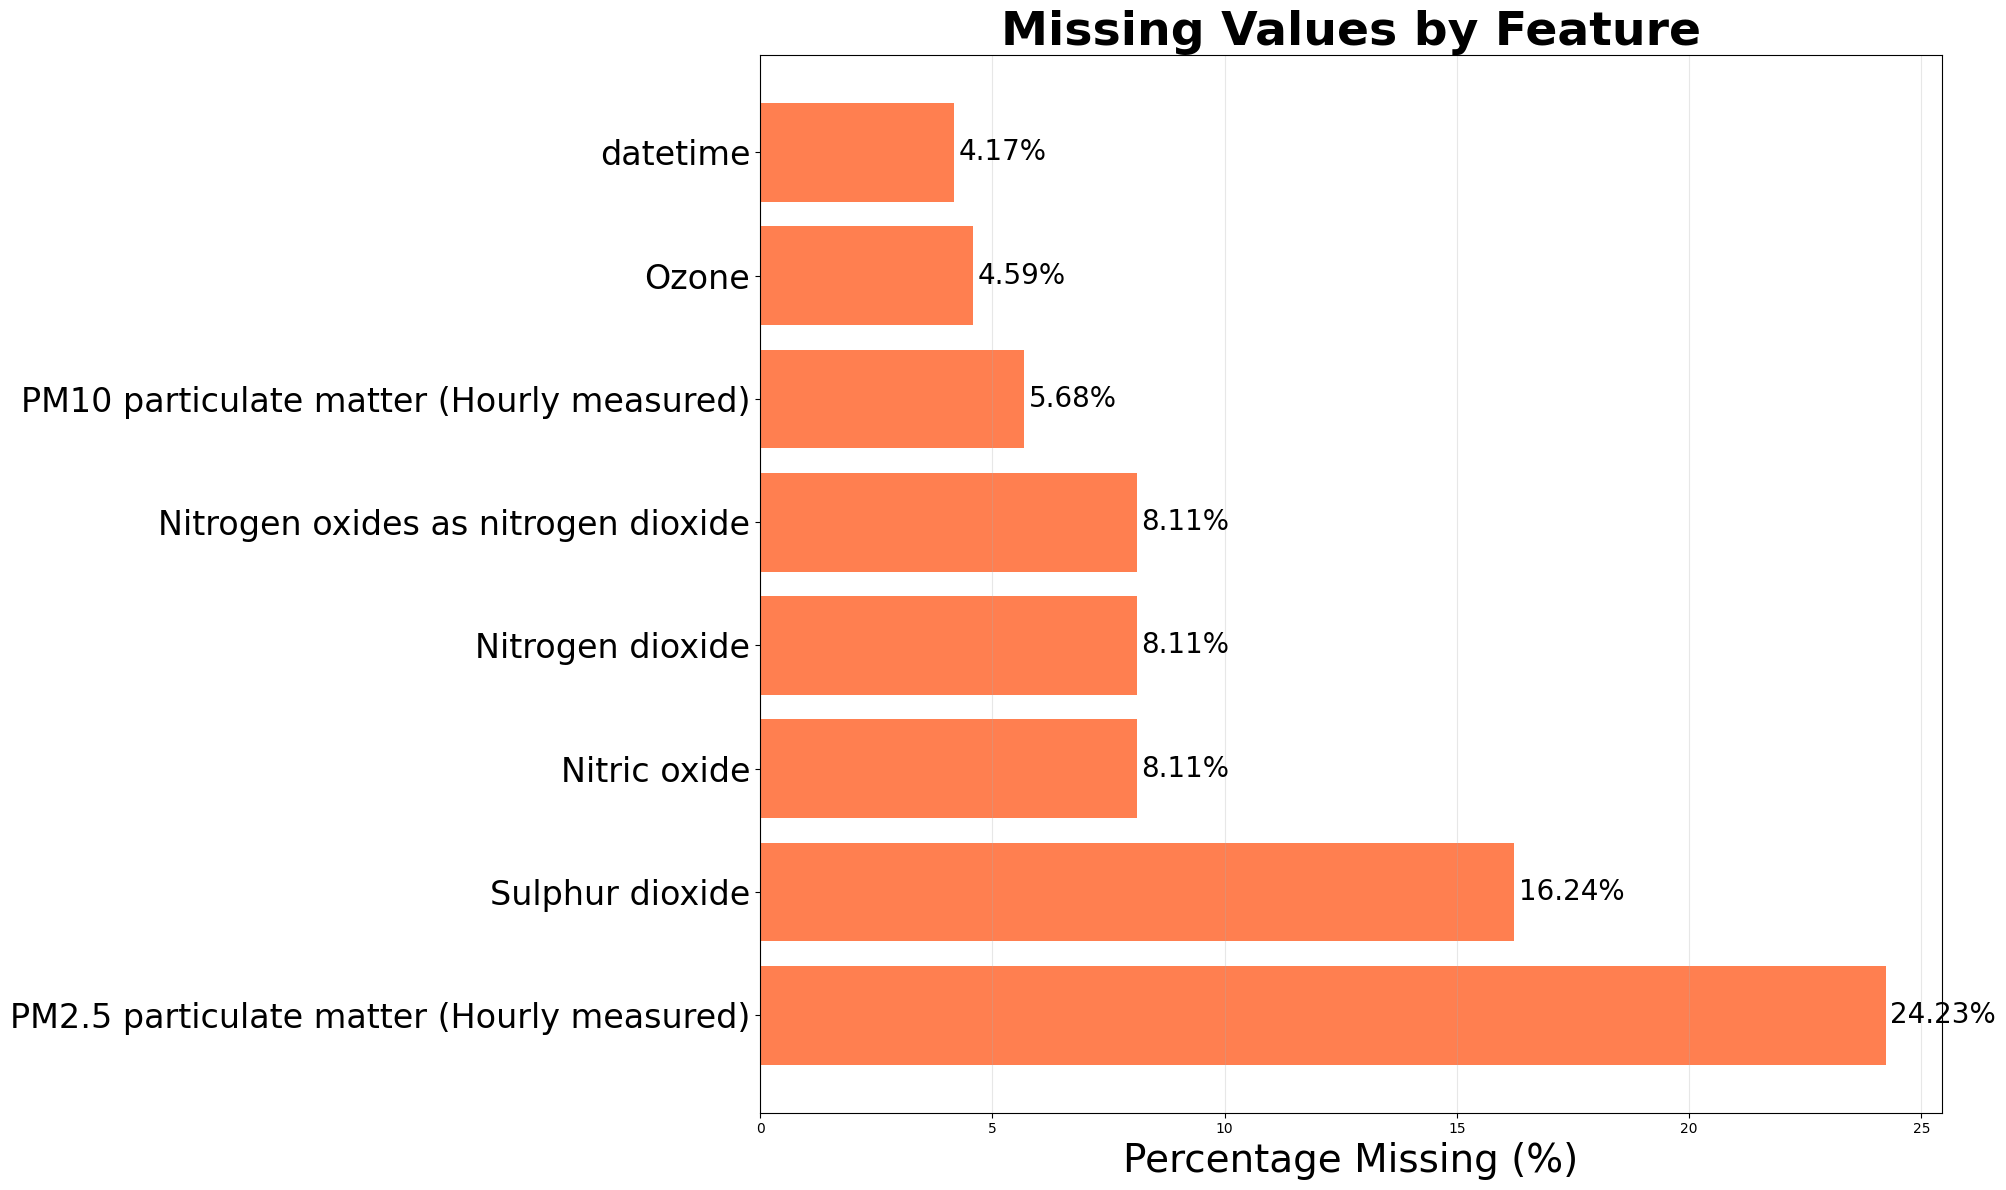

In [ ]:
# Check for missing values before dropping
missing_values = df_raw.isnull().sum()
missing_percentage = (df_raw.isnull().sum() / len(df_raw)) * 100

missing_df = pd.DataFrame({
    'Missing Count': missing_values,
    'Percentage': missing_percentage
})

print("Missing Values Summary:\n")
print(missing_df[missing_df['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False))

# Visualise missing values
fig, ax = plt.subplots(figsize=(20, 12))
missing_cols = missing_df[missing_df['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False)
if len(missing_cols) > 0:
    ax.barh(missing_cols.index, missing_cols['Percentage'], color='coral')
    ax.set_xlabel('Percentage Missing (%)', fontsize=28)
    ax.set_title('Missing Values by Feature', fontsize=34, fontweight='bold')
    ax.tick_params(axis="y", labelsize=24)
    ax.grid(axis='x', alpha=0.3)
    for i, v in enumerate(missing_cols['Percentage']):
        ax.text(v + 0.1, i, f'{v:.2f}%', va='center', fontsize=20)
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found in the dataset.")

### d.8) Dropping missing rows for PM10

In [ ]:
df_raw = df_raw.dropna(subset=["PM10 particulate matter (Hourly measured)"])
df_raw.isna().sum()

PM10 particulate matter (Hourly measured)        0
Nitric oxide                                  2857
Nitrogen dioxide                              2857
Nitrogen oxides as nitrogen dioxide           2857
Ozone                                         1315
PM2.5 particulate matter (Hourly measured)    8908
Sulphur dioxide                               5942
year                                             0
datetime                                      1731
dtype: int64

### d.9) Dropping rows with missing datetime

In [ ]:
df_raw = df_raw.dropna(subset = ["datetime"])

### d.10) Interpolate missing pollutant values
- fills gaps smoothly using time-based interpolationd.

In [ ]:
## coverting datetime column to DatetimeIndex
df_raw["datetime"] = pd.to_datetime(df_raw["datetime"])
df_raw = df_raw.set_index("datetime")

## time-based interpolation
df_raw = df_raw.interpolate(method="time")
df_raw

,PM10 particulate matter (Hourly measured),Nitric oxide,Nitrogen dioxide,Nitrogen oxides as nitrogen dioxide,Ozone,PM2.5 particulate matter (Hourly measured),Sulphur dioxide,year
datetime,,,,,,,,
2019-01-04 20:00:00,43.100,32.20150,81.42417,130.79912,2.89377,30.400,3.18405,2019
2019-01-04 21:00:00,40.700,24.79959,74.36997,112.39548,2.64430,30.300,2.91307,2019
2019-01-04 22:00:00,43.500,20.75068,64.69089,96.50814,2.84387,31.800,2.70983,2019
2019-01-04 23:00:00,30.600,14.58241,57.52134,79.88072,4.93936,29.000,2.98082,2019
2019-01-05 01:00:00,33.600,8.75206,54.60069,68.02033,4.98925,27.900,0.72191,2019
...,...,...,...,...,...,...,...,...
2023-12-22 21:00:00,6.575,3.42735,34.45761,39.71280,52.73637,3.821,0.26313,2023
2023-12-22 22:00:00,6.025,2.03605,28.17806,31.29996,53.93379,3.868,0.26313,2023
2023-12-22 23:00:00,5.425,0.57688,27.07119,27.95572,49.29379,3.349,0.39470,2023


### d.11) Forward-fill any remaining gaps

In [ ]:
df_raw = df_raw.fillna(method="ffill")

## resetting datetime index again

df_raw = df_raw.reset_index()

### d.12) Creating cleaned csv file saved in cleaned folder

In [ ]:
df_cleaned = df_raw
df_cleaned.to_csv("../data/cleaned/bloomsbury_cleaned.csv", index=False)
print("File saved!")

File saved!


## e) Exploratory Data Analysis

### e.1) Summary Statistics

In [ ]:
print("Descriptive Statistics:")
print("\n" + "="*80)
print(df_cleaned.describe())

print("\n" + "="*80)
print("Additional Statistics:\n")

# columns to be in additional description
cols_for_description = [
    col for col in df_cleaned.columns
    if col not in ["datetime", "year", "index"]
]
stats_table = pd.DataFrame({
    "Mean": df_cleaned[cols_for_description].mean(),
    "Median": df_cleaned[cols_for_description].median(),
    "Std Dev": df_cleaned[cols_for_description].std(),
    "Skewness": df_cleaned[cols_for_description].skew(),
    "Kurtosis": df_cleaned[cols_for_description].kurt()
})

stats_table = stats_table.round({
    "Mean": 2,
    "Median": 2,
    "Std Dev": 2,
    "Skewness": 3,
    "Kurtosis": 3
})

stats_table

Descriptive Statistics:

                            datetime  \
count                          39603   
mean   2021-07-15 19:51:06.585864960   
min              2019-01-04 20:00:00   
25%              2020-04-13 17:30:00   
50%              2021-07-26 21:00:00   
75%              2022-10-16 22:30:00   
max              2023-12-23 02:00:00   
std                              NaN   

       PM10 particulate matter (Hourly measured)  Nitric oxide  \
count                               39603.000000  39603.000000   
mean                                   16.007511      6.610844   
min                                    -3.768000     -0.031180   
25%                                     9.500000      1.040540   
50%                                    13.527000      2.431290   
75%                                    19.400000      6.464720   
max                                   194.125000    289.385360   
std                                    10.655516     13.118635   

       Nitrogen dio

,Mean,Median,Std Dev,Skewness,Kurtosis
PM10 particulate matter (Hourly measured),16.01,13.53,10.66,2.687,14.646
Nitric oxide,6.61,2.43,13.12,6.117,59.094
Nitrogen dioxide,27.22,23.15,16.88,1.141,1.276
Nitrogen oxides as nitrogen dioxide,37.36,27.53,33.66,3.272,19.023
Ozone,44.17,44.24,23.06,0.494,1.226
PM2.5 particulate matter (Hourly measured),9.07,7.40,7.30,3.505,22.033
Sulphur dioxide,1.19,1.00,1.19,28.287,1808.741


### e.2) Time-Series Plots

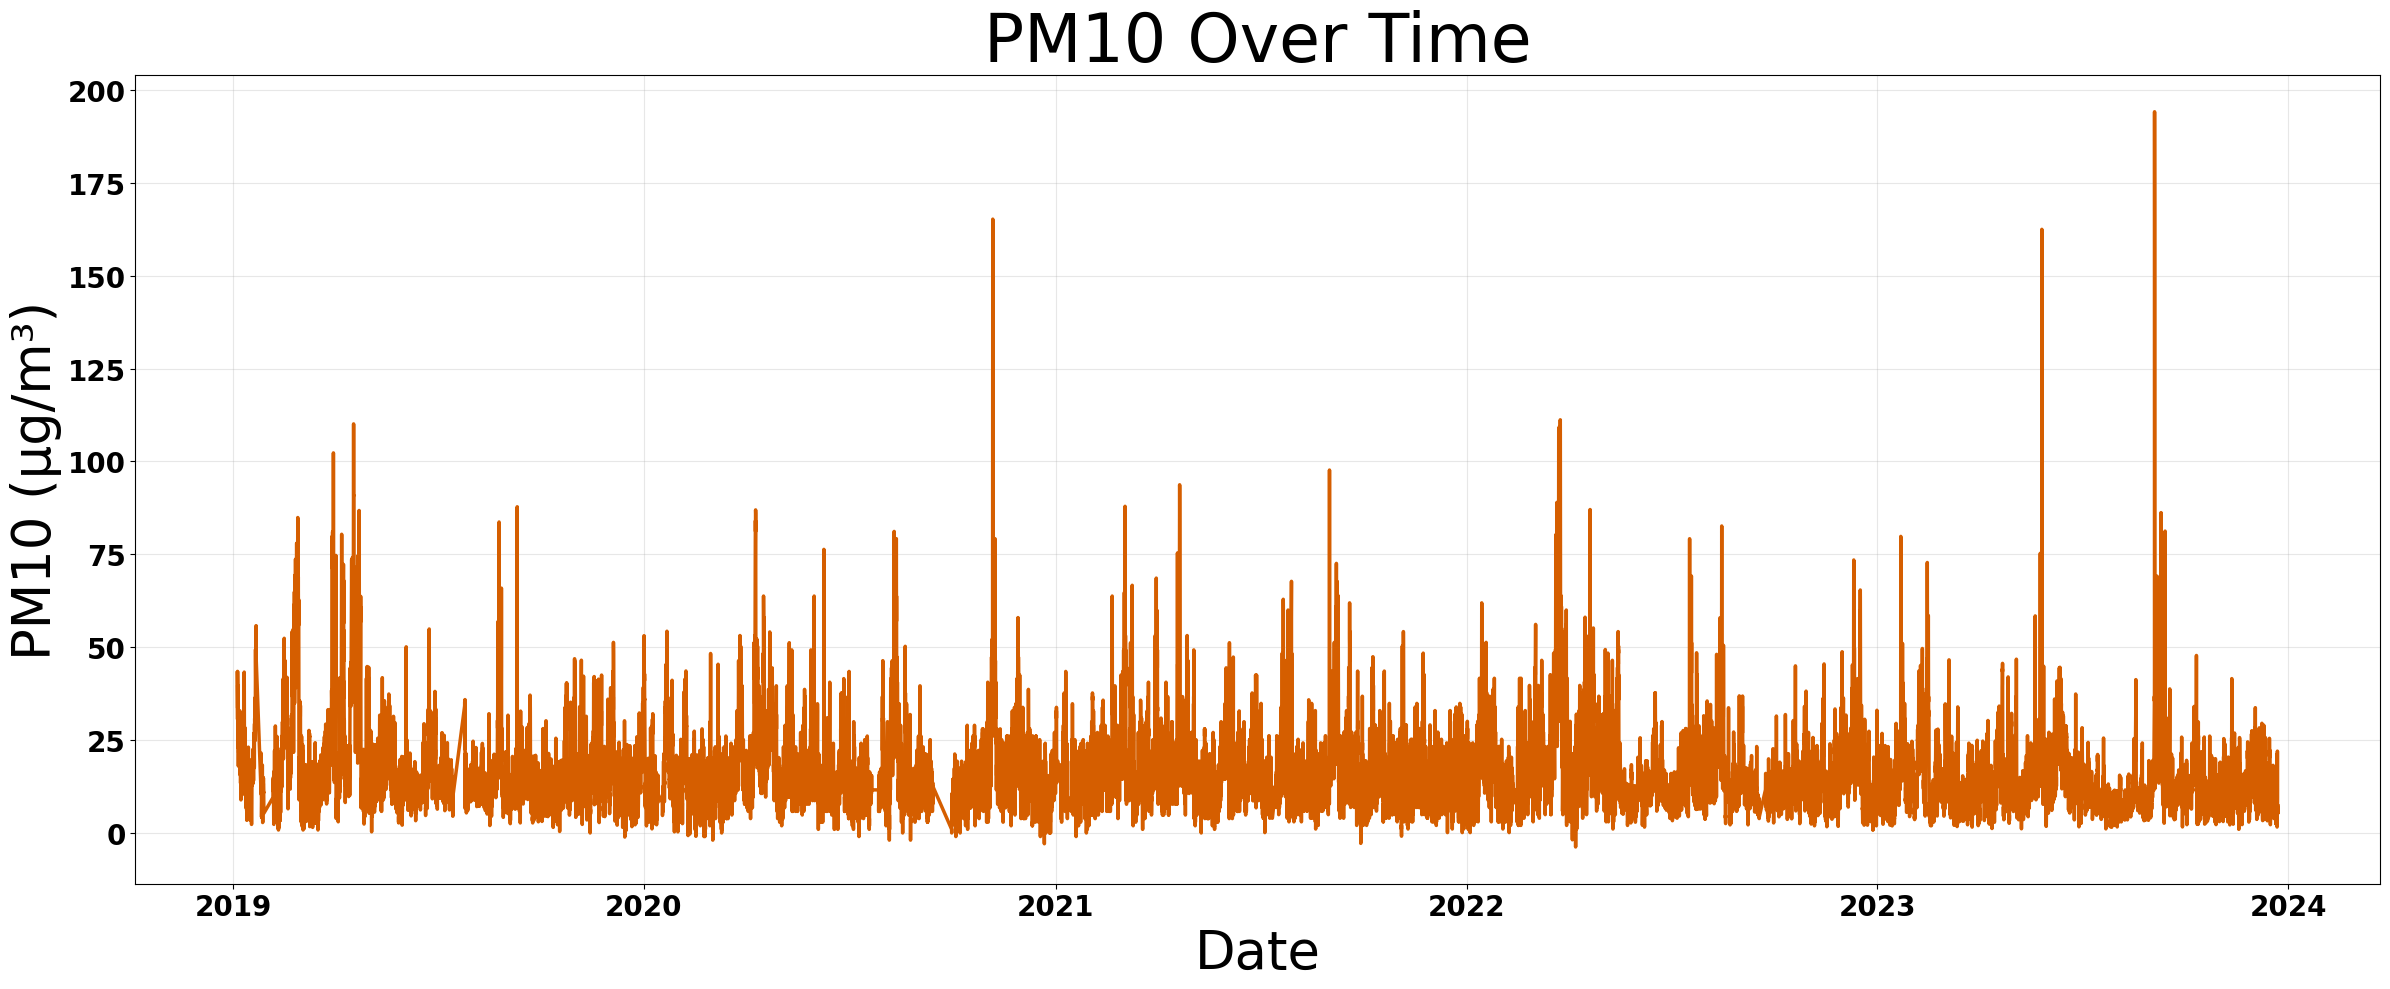

In [ ]:
plt.figure(figsize=(24,10))
plt.plot(df_cleaned["datetime"], df_cleaned["PM10 particulate matter (Hourly measured)"], color="#D55E00", linewidth=2.5)
plt.title("PM10 Over Time", fontsize=48)
plt.xlabel("Date", fontsize=38)
plt.ylabel("PM10 (µg/m³)", fontsize=38)
plt.xticks(fontsize=20, fontweight="bold")
plt.yticks(fontsize=20, fontweight="bold")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### e.3) Time-Series Plots for all Pollutants

Time Series plot for all Polutants


<Figure size 640x480 with 0 Axes>

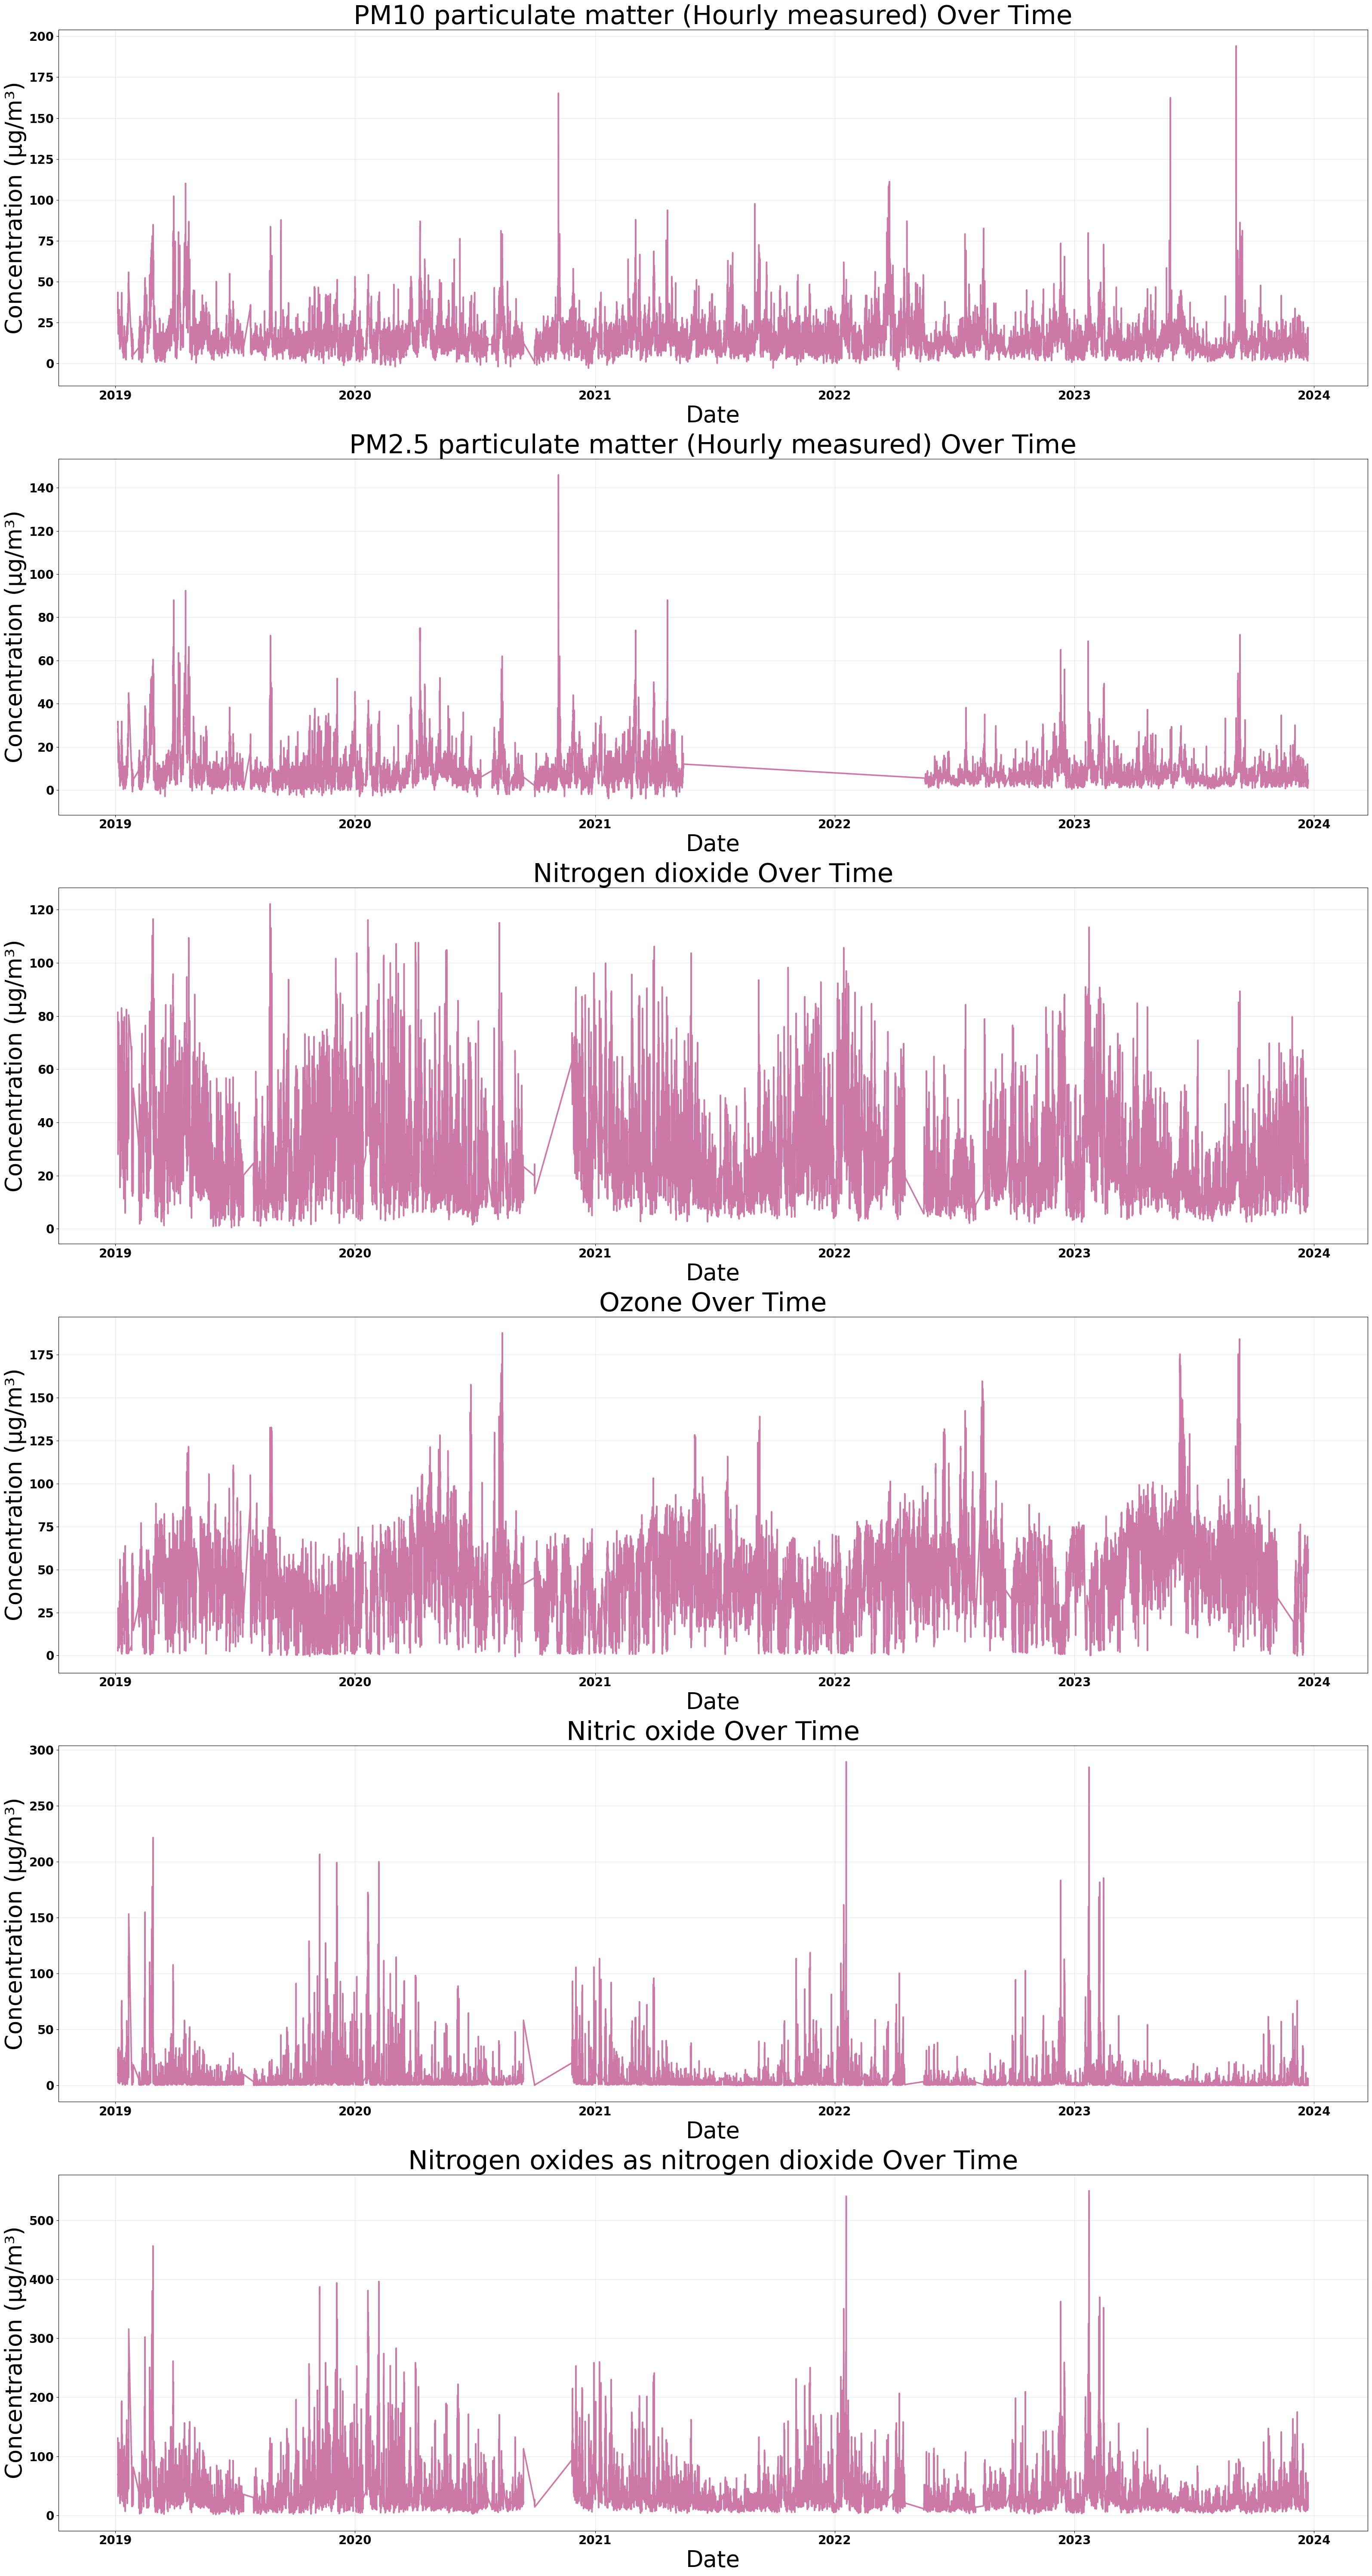

In [ ]:
pollutants = [
    "PM10 particulate matter (Hourly measured)",
    "PM2.5 particulate matter (Hourly measured)",
    "Nitrogen dioxide",
    "Ozone",
    "Nitric oxide",
    "Nitrogen oxides as nitrogen dioxide"
]

print("Time Series plot for all Polutants")
plt.figure(figsize=(32,60))
for i, col in enumerate(pollutants, 1):
    plt.subplot(6, 1, i)
    plt.plot(df_cleaned["datetime"], df_cleaned[col], label=col, color="#CC79A7", linewidth=2.5)
    plt.title(f"{col} Over Time", fontsize=44)
    plt.xlabel("Date", fontsize=38)
    plt.ylabel("Concentration (µg/m³)", fontsize=38)
    plt.xticks(fontsize=20, fontweight="bold")
    plt.yticks(fontsize=20, fontweight="bold")
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### e.4) Pollutant Distribution Plots
- Histograms and KDE curves

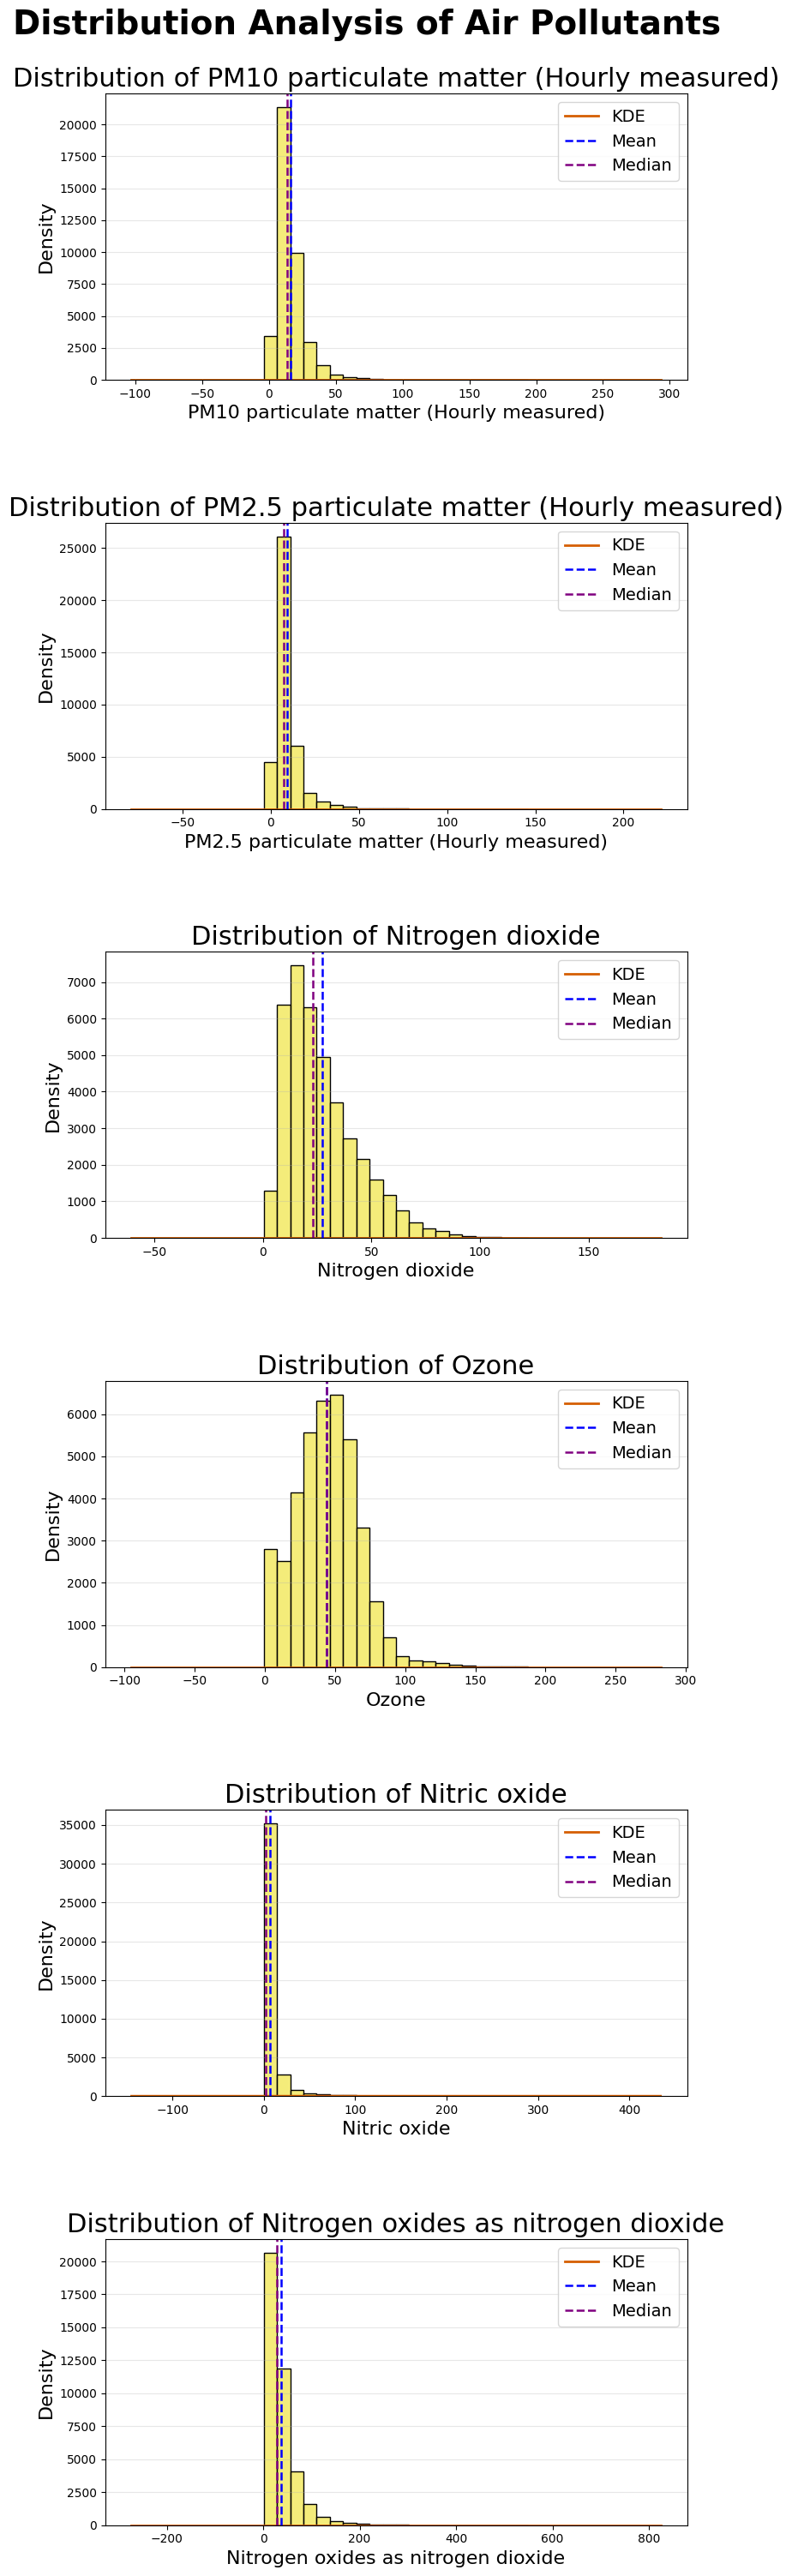

In [ ]:
fig, axes = plt.subplots(
    nrows=len(pollutants),
    ncols=1,
    figsize=(8, 5 *len(pollutants))
)

fig.suptitle("Distribution Analysis of Air Pollutants", fontsize=28, fontweight="bold", y=1.0)

for idx, col in enumerate(pollutants):
    ax = axes[idx]

    #histogram
    sns.histplot(
        df_cleaned[col], bins=20, kde=False, color="#F0E442", edgecolor="black", alpha=0.7, ax=ax
    )

    #Kde curve
    df_cleaned[col].plot(kind="density", ax=ax, color="#D55E00",
    linewidth=2, label="KDE")

    #Titles and labels
    ax.set_title(f"Distribution of {col}", fontsize=22)
    ax.set_xlabel(col, fontsize=16)
    ax.set_ylabel("Density", fontsize=16)

    # mean and median lines
    mean_val = df_cleaned[col].mean()
    median_val = df_cleaned[col].median()

    ax.axvline(mean_val, color="blue", linestyle="dashed", linewidth=1.8, label="Mean")
    ax.axvline(median_val, color="purple", linestyle="dashed", linewidth=1.8, label="Median")
    ax.legend(fontsize=14)
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.subplots_adjust(hspace=0.5)
plt.show()


### e.6) Seasonal Patterns Analysis
- Monthly averages
- Day-of-week patterns

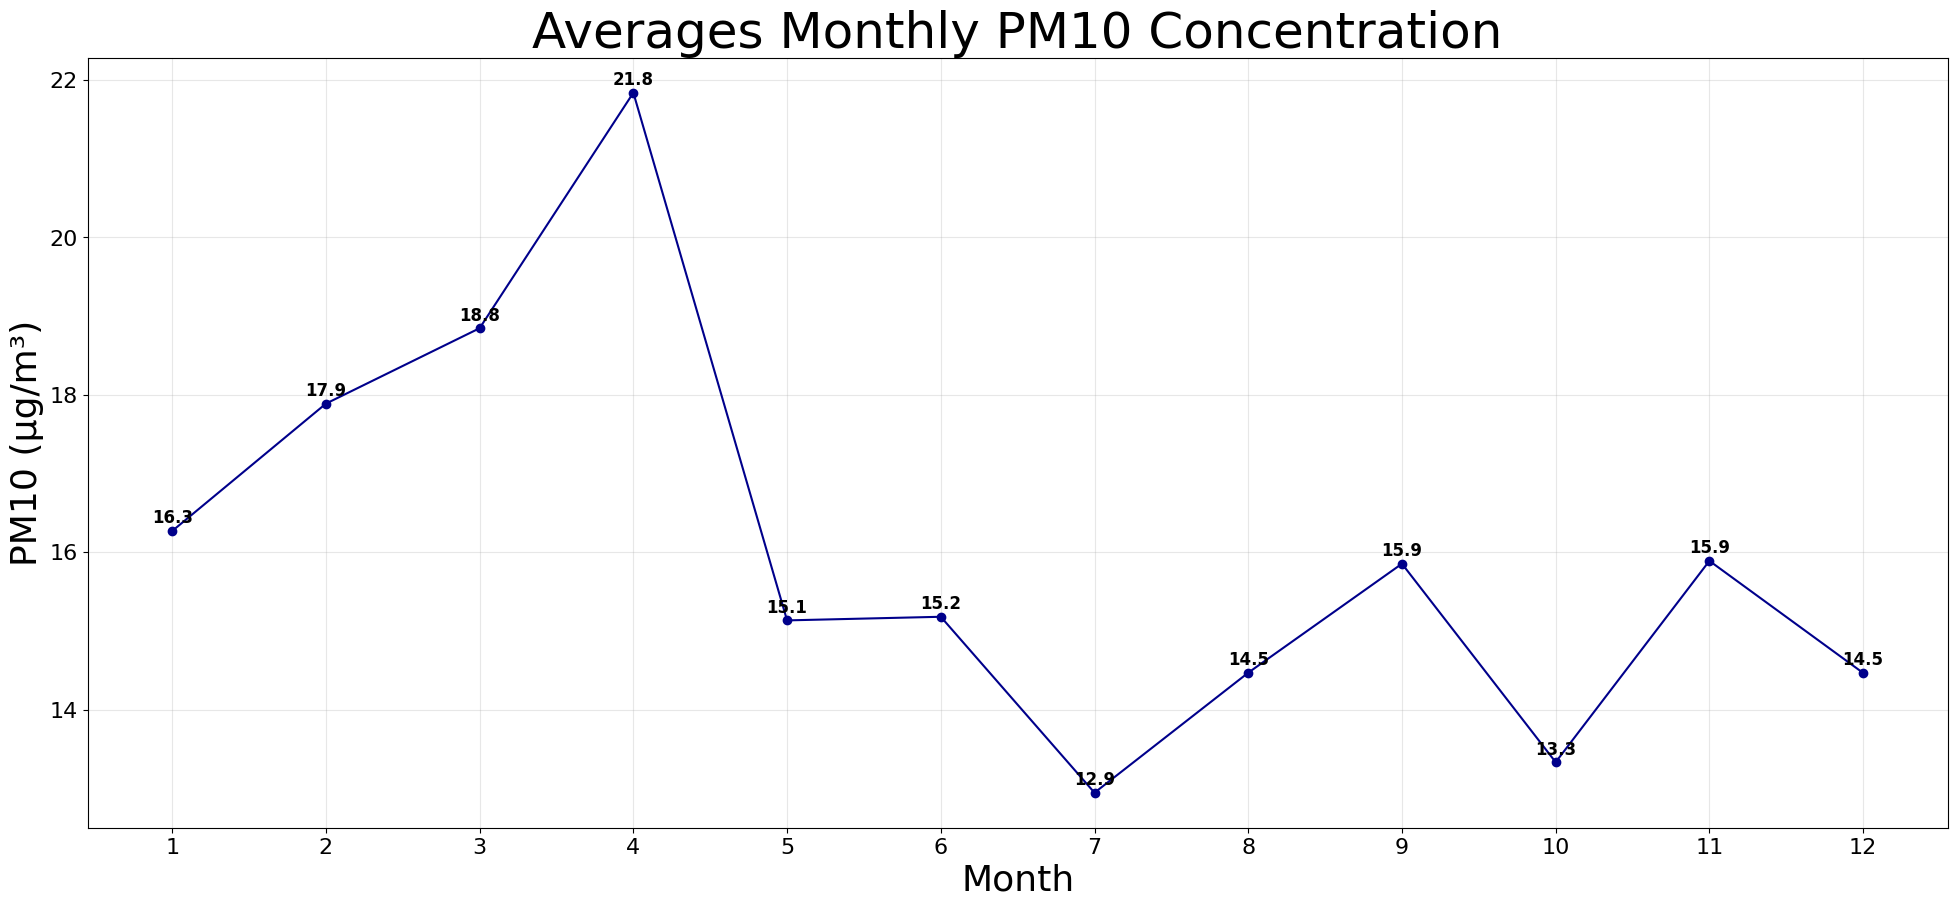

In [ ]:
## Monthly seasonal patterns for PM10
df_cleaned ["month"] = df_cleaned["datetime"].dt.month

monthly_avg = df_cleaned.groupby("month")["PM10 particulate matter (Hourly measured)"].mean()

plt.figure(figsize=(24, 10))
plt.plot(monthly_avg.index, monthly_avg.values, marker="o", color="darkblue")
plt.title("Averages Monthly PM10 Concentration", fontsize=36)
plt.xlabel("Month", fontsize=26)
plt.ylabel("PM10 (µg/m³)", fontsize=26)
plt.grid(True, alpha=0.3)
plt.xticks(range(1,13), fontsize=16)
plt.yticks(fontsize=16)
for x, y in zip(monthly_avg.index, monthly_avg.values):
    plt.text(x, y+0.1, f"{y:.1f}", fontsize=12, color="black", ha="center", fontweight="bold")
plt.show()

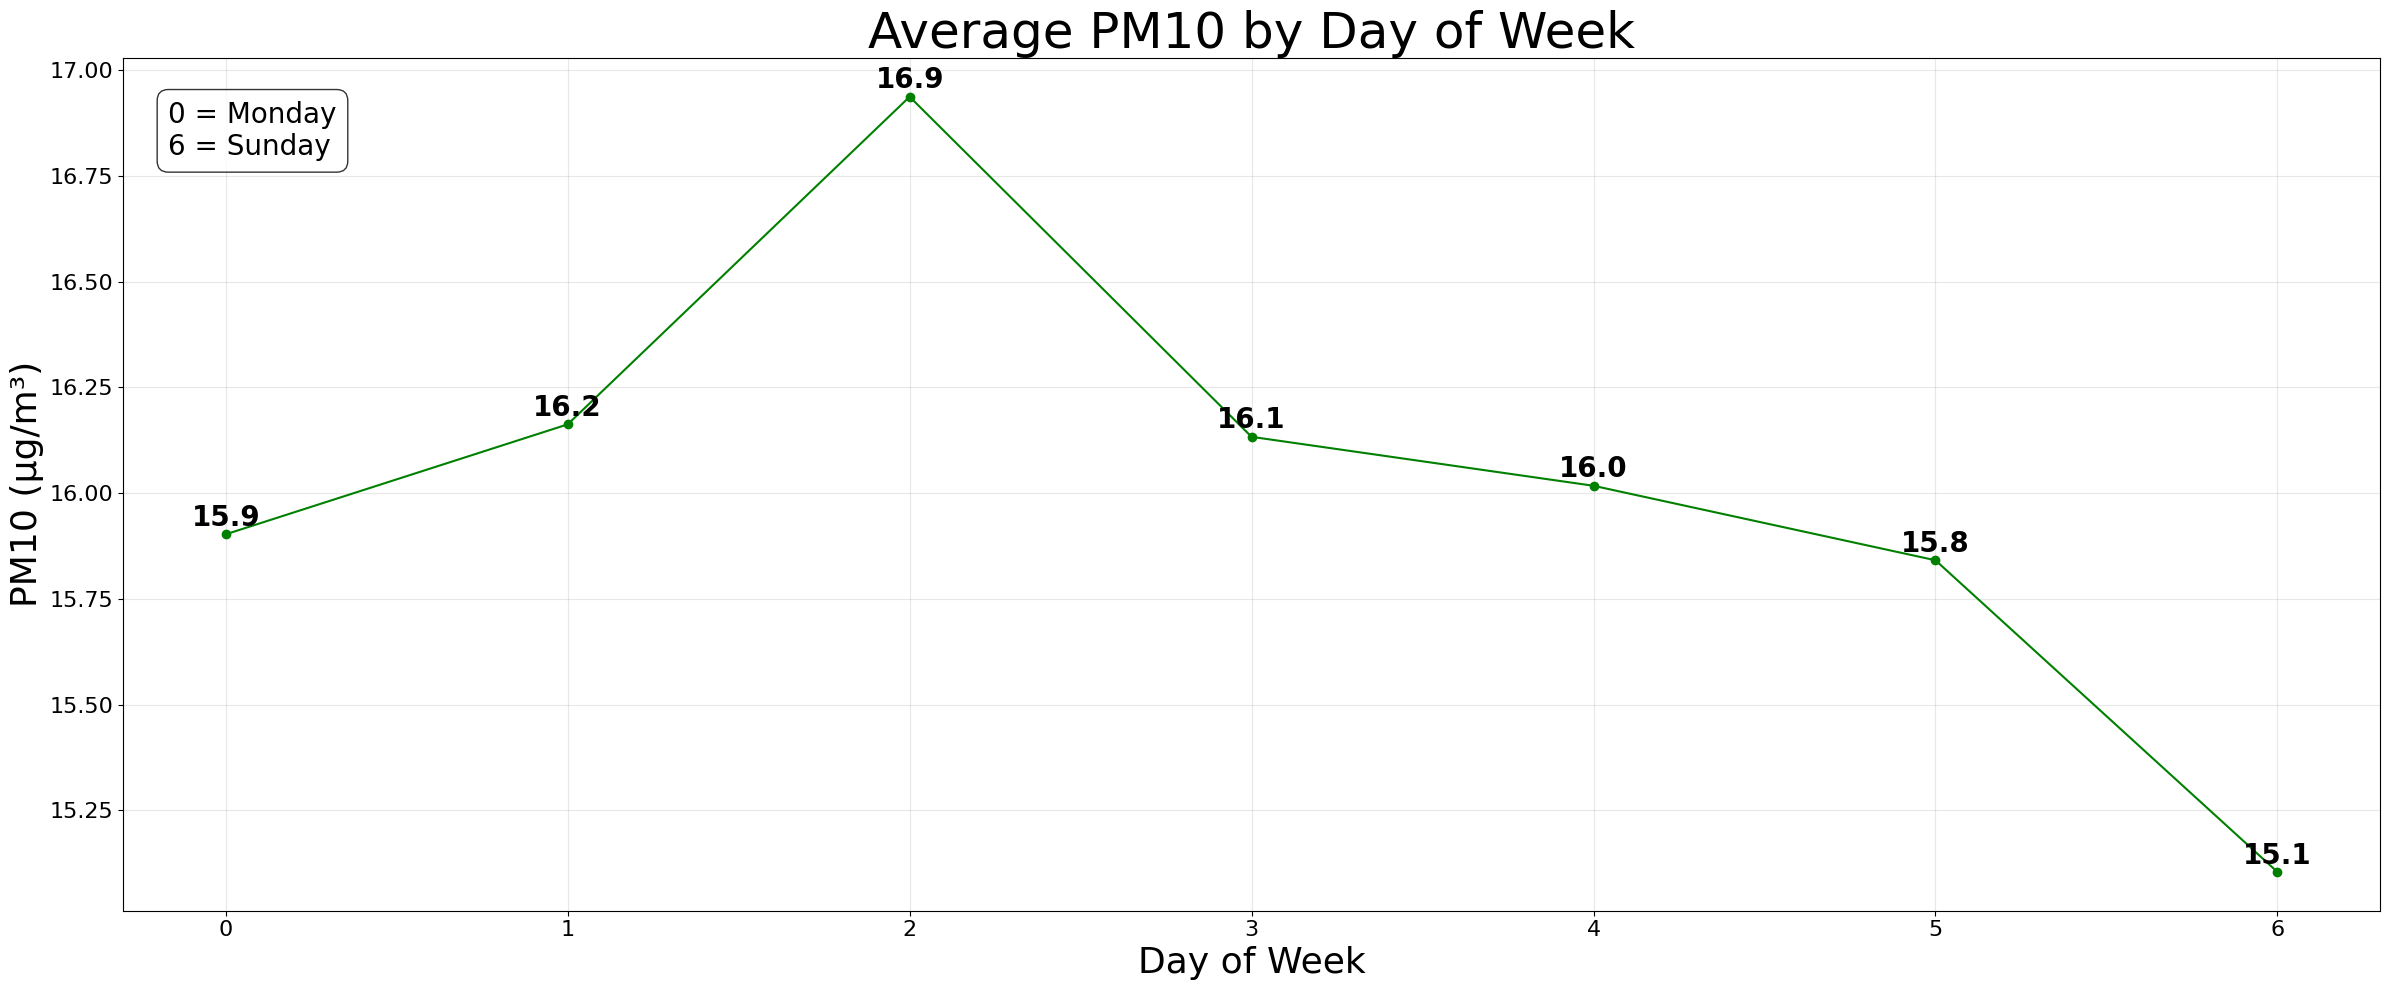

In [ ]:
## Day-of-week pattern for PM10
## 0= Monday, 6= Sunday
df_cleaned["day_of_week"] = df_cleaned["datetime"].dt.dayofweek
dow_avg = df_cleaned.groupby("day_of_week")["PM10 particulate matter (Hourly measured)"].mean()

plt.figure(figsize=(24, 10))
plt.plot(dow_avg.index, dow_avg.values, marker="o", color="green")
plt.title("Average PM10 by Day of Week", fontsize=36)
plt.xlabel("Day of Week", fontsize=26)
plt.ylabel("PM10 (µg/m³)", fontsize=26)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.grid(True, alpha=0.3)
for x, y in zip(dow_avg.index, dow_avg.values):
    plt.text(x, y+0.02, f"{y:.1f}", fontsize=20, color="black", ha="center", fontweight="bold")
plt.tight_layout()
ax=plt.gca()
ax.text(0.02, 0.95, "0 = Monday\n6 = Sunday", transform=ax.transAxes, fontsize=20, verticalalignment="top", bbox=dict(facecolor="white", edgecolor="black", boxstyle="round, pad=0.4", alpha=0.8))
plt.show()

### e.8) Outlier Detection Plot

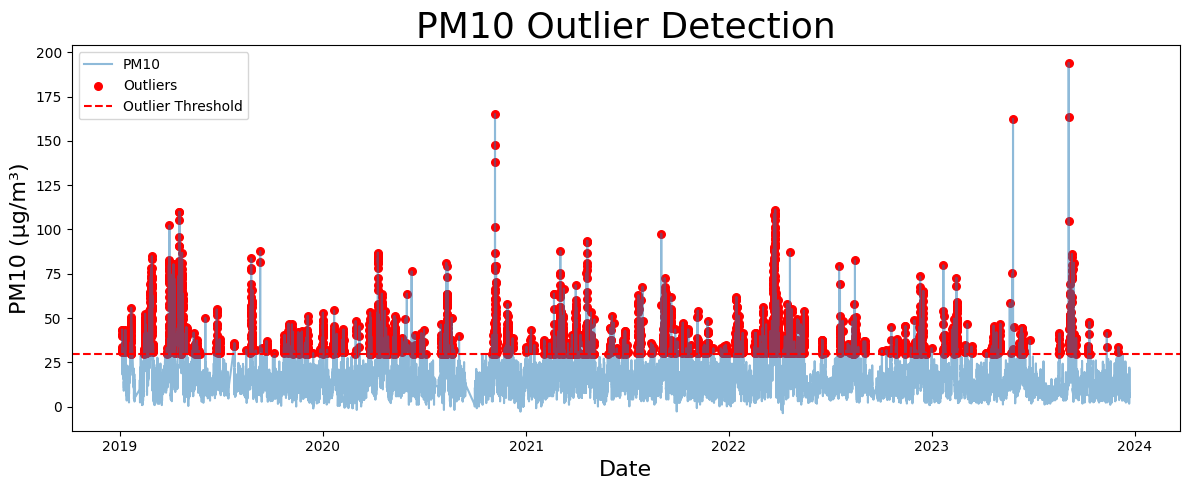

In [ ]:
pm10 = df_cleaned["PM10 particulate matter (Hourly measured)"]
threshold = pm10.mean() + 3+ pm10.std()

outliers = df_cleaned[df_cleaned["PM10 particulate matter (Hourly measured)"] > threshold]

plt.figure(figsize=(12,5))
plt.plot(df_cleaned["datetime"], pm10, label="PM10", alpha=0.5)
plt.scatter(outliers["datetime"], outliers["PM10 particulate matter (Hourly measured)"], color="red", label="Outliers", s=30)
plt.axhline(threshold, color="red", linestyle="--", label="Outlier Threshold")
plt.title("PM10 Outlier Detection", fontsize=26)
plt.xlabel("Date", fontsize=16)
plt.ylabel("PM10 (µg/m³)", fontsize=16)
plt.legend()
plt.tight_layout()
plt.show()

### e.10) Creating csv file for monthly and day of week averages in cleaned folder

In [ ]:

df_cleaned.to_csv("../data/cleaned/monthly_avg.csv", index=False)
df_cleaned.to_csv("../data/cleaned/dow_avg.csv", index=False)

## f) Feature Engineering
- Lag Features
- Rolling averages
- Temporal features
- Dropping NaNs created by these features

### f.1) Lag Features

In [ ]:
print(df_cleaned.columns.tolist())

['datetime', 'PM10 particulate matter (Hourly measured)', 'Nitric oxide', 'Nitrogen dioxide', 'Nitrogen oxides as nitrogen dioxide', 'Ozone', 'PM2.5 particulate matter (Hourly measured)', 'Sulphur dioxide', 'year', 'month', 'day_of_week']


In [ ]:
lag_cols = [
    "PM2.5 particulate matter (Hourly measured)",
    "Nitrogen dioxide",
    "Ozone"
]

for col in lag_cols:
    df_cleaned[col + "_lag1"] = df_cleaned[col].shift(1)

### f.2) Rolling Averages

In [ ]:
for col in lag_cols:
    df_cleaned[col + "_roll3"] = df_cleaned[col].rolling(window=3).mean()

### f.3) Temporal Features

In [ ]:
df_cleaned["month"] = df_cleaned["datetime"].dt.month
df_cleaned["day_of_week"] = df_cleaned["datetime"].dt.dayofweek

### f.4) Dropping NaNs

In [ ]:
df_cleaned = df_cleaned.dropna()

### f.5) Defining target variable (y)

In [ ]:
y = df_cleaned["PM10 particulate matter (Hourly measured)"]

### f.6) Defining feature set (x)

In [ ]:
X = df_cleaned.drop(columns=[
    "PM10 particulate matter (Hourly measured)",
    "datetime"
])

pd.DataFrame({"Feature": X.columns})

,Feature
0,Nitric oxide
1,Nitrogen dioxide
2,Nitrogen oxides as nitrogen dioxide
3,Ozone
4,PM2.5 particulate matter (Hourly measured)
5,Sulphur dioxide
6,year
7,month
8,day_of_week
9,PM2.5 particulate matter (Hourly measured)_lag1


### f.7) Confirming shapes

In [ ]:
X.shape, y.shape

((39601, 15), (39601,))

### e.5) Correlation Heatmap 

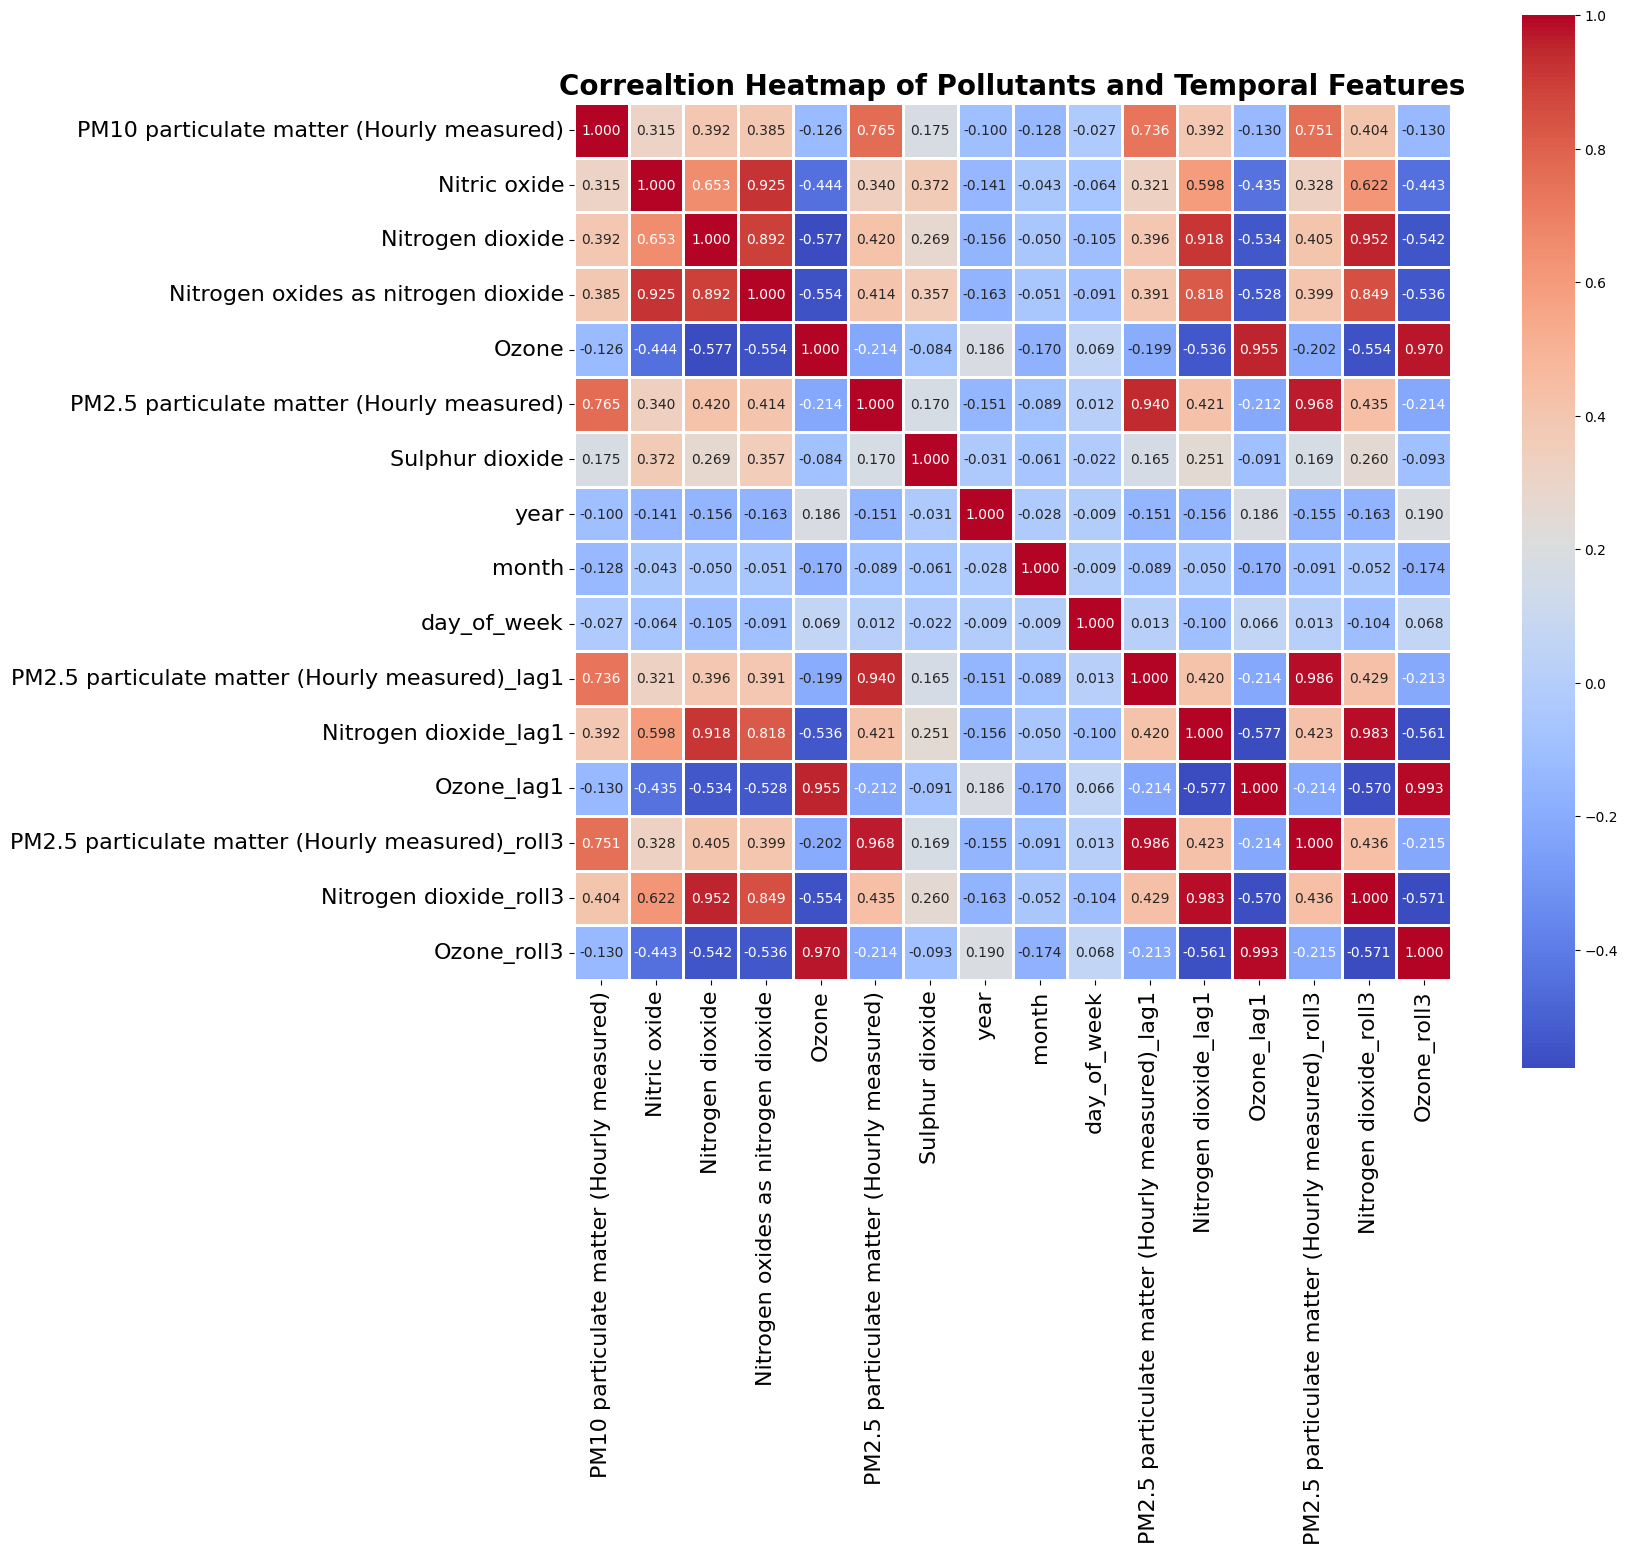

In [ ]:
df_corr = df_cleaned.drop(columns=["index"], errors="ignore")

corr = df_corr.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(20, 16))
sns.heatmap(corr, cmap="coolwarm", annot=True, linewidths=1, fmt='.3f', square=True, cbar_kws={"shrink": 1.2})
ax.set_title("Correaltion Heatmap of Pollutants and Temporal Features", fontsize=20, fontweight='bold')
ax.tick_params(axis="x", labelsize=16, rotation=90)
ax.tick_params(axis="y", labelsize=16, rotation=0)
plt.tight_layout()
plt.show()

## g) Modelling

### g.1) Train/Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False
)

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((31680, 15), (7921, 15), (31680,), (7921,))

### g.2) Model Training

#### Model 1: Linear Regression Model
- Train Linear Regression Model

In [ ]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)

- Evaluate Linear Regression Model

In [ ]:
r2_lr = r2_score(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))

print("Linear Regression R2:", r2_lr)
print("Linear Regression RMSE:", rmse_lr)

Linear Regression R2: 0.5723824259394608
Linear Regression RMSE: 5.844047514367699


- Actual Vs Predicted Plot

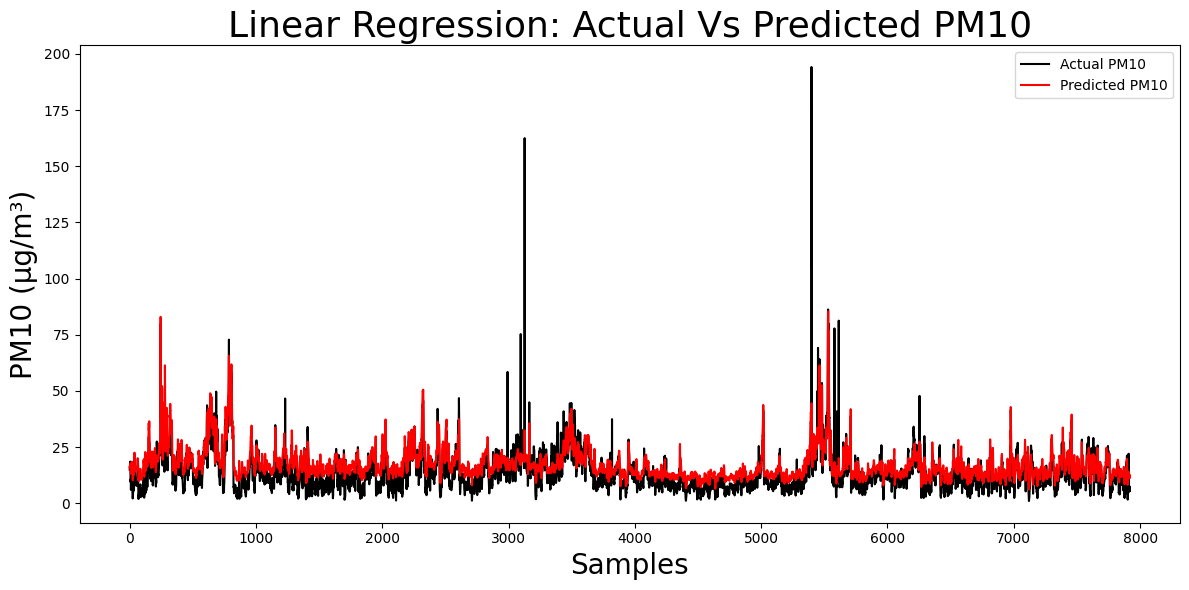

In [ ]:
plt.figure(figsize=(12,6))
plt.plot(y_test.values,label="Actual PM10", color="black")
plt.plot(y_pred_lr, label="Predicted PM10", color="red")
plt.title("Linear Regression: Actual Vs Predicted PM10", fontsize=26)
plt.xlabel("Samples", fontsize=20)
plt.ylabel("PM10 (µg/m³)", fontsize=20)
plt.legend()
plt.tight_layout()
plt.show()

- Residual Plot

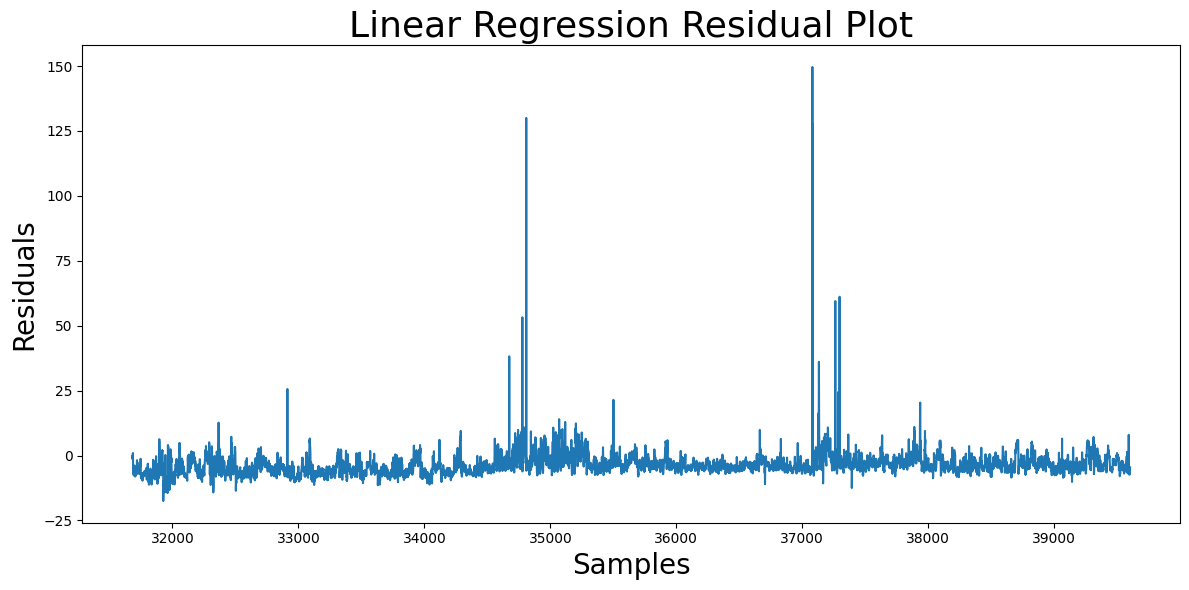

In [ ]:
residuals_lr = y_test - y_pred_lr

plt.figure(figsize=(12, 6))
plt.plot(residuals_lr)
plt.title("Linear Regression Residual Plot", fontsize=26)
plt.xlabel("Samples", fontsize=20)
plt.ylabel("Residuals", fontsize=20)
plt.tight_layout()
plt.show()

- Error distribution plot

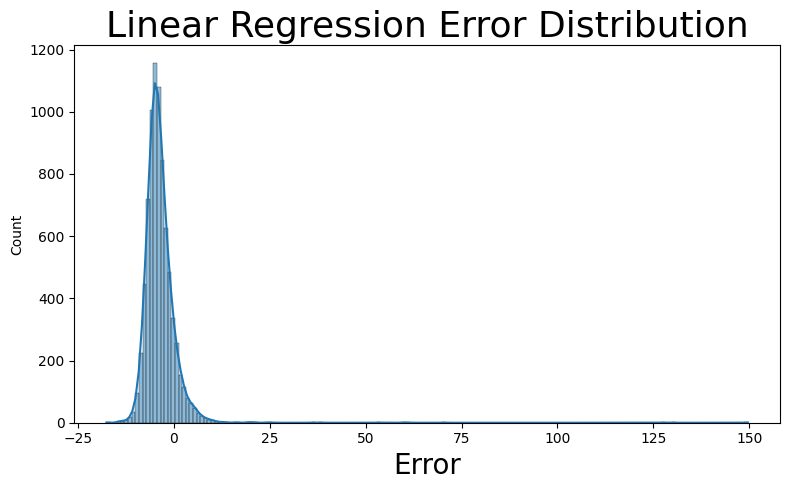

In [ ]:
## Linear Regression 

plt.figure(figsize=(8,5))
sns.histplot(residuals_lr, kde=True)
plt.xlabel("Error", fontsize=20)
plt.title("Linear Regression Error Distribution", fontsize=26)
plt.tight_layout()
plt.show()

- Actual Vs Predicted Scatter Plot

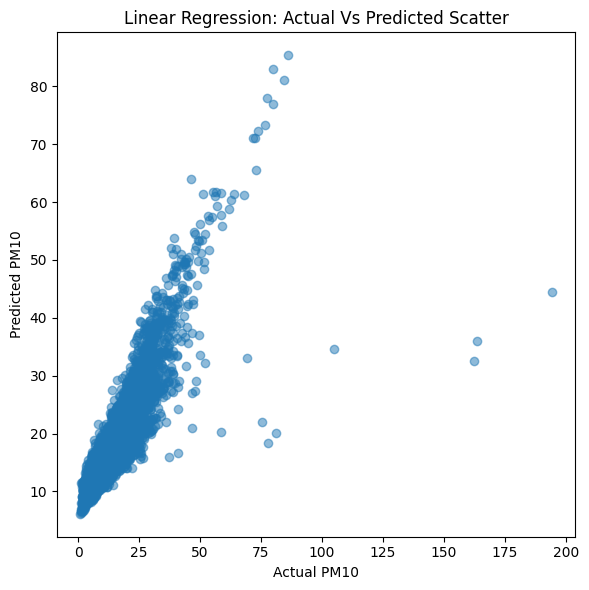

In [ ]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred_lr, alpha=0.5)
plt.xlabel("Actual PM10")
plt.ylabel("Predicted PM10")
plt.title("Linear Regression: Actual Vs Predicted Scatter")
plt.tight_layout()
plt.show()

#### Model 2: Random Forest Model

In [ ]:
feature_list = X.columns.tolist()
print("Training features:", feature_list)

Training features: ['Nitric oxide', 'Nitrogen dioxide', 'Nitrogen oxides as nitrogen dioxide', 'Ozone', 'PM2.5 particulate matter (Hourly measured)', 'Sulphur dioxide', 'year', 'month', 'day_of_week', 'PM2.5 particulate matter (Hourly measured)_lag1', 'Nitrogen dioxide_lag1', 'Ozone_lag1', 'PM2.5 particulate matter (Hourly measured)_roll3', 'Nitrogen dioxide_roll3', 'Ozone_roll3']


- Train Random Forest Model

In [ ]:
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

- Evaluate Random Forest model

In [ ]:
r2_rf = r2_score(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

print("Random Forest R2:", r2_rf)
print("Random Forest RMSE:", rmse_rf)

Random Forest R2: 0.7083138092148116
Random Forest RMSE: 4.826628800929966


- Actual Vs Predicted Plot

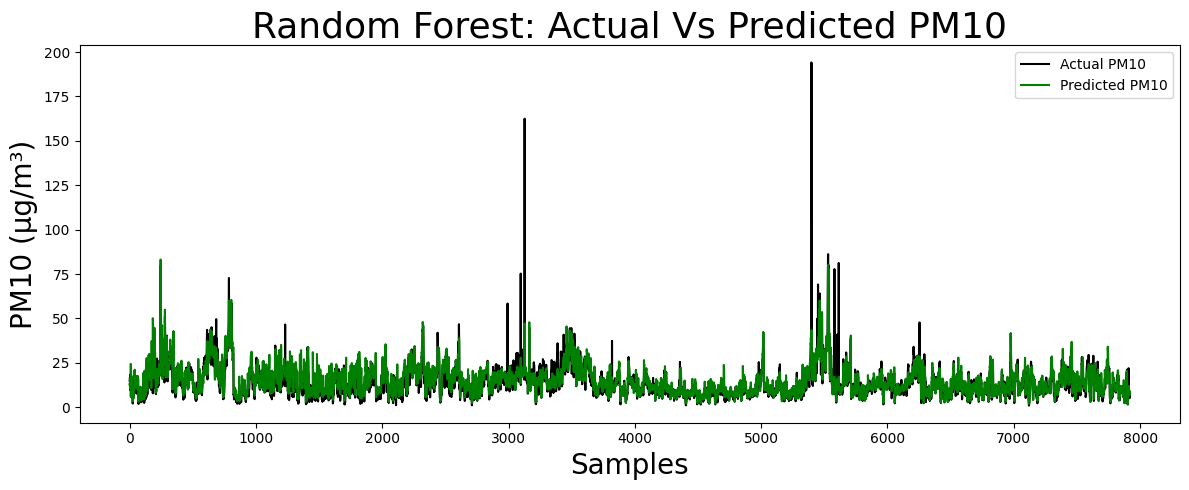

In [ ]:
plt.figure(figsize=(12,5))
plt.plot(y_test.values, label="Actual PM10", color="black")
plt.plot(y_pred_rf, label="Predicted PM10", color="green")
plt.title("Random Forest: Actual Vs Predicted PM10", fontsize=26)
plt.xlabel("Samples", fontsize=20)
plt.ylabel("PM10 (µg/m³)", fontsize=20)
plt.legend()
plt.tight_layout()
plt.show()

- Residual plot

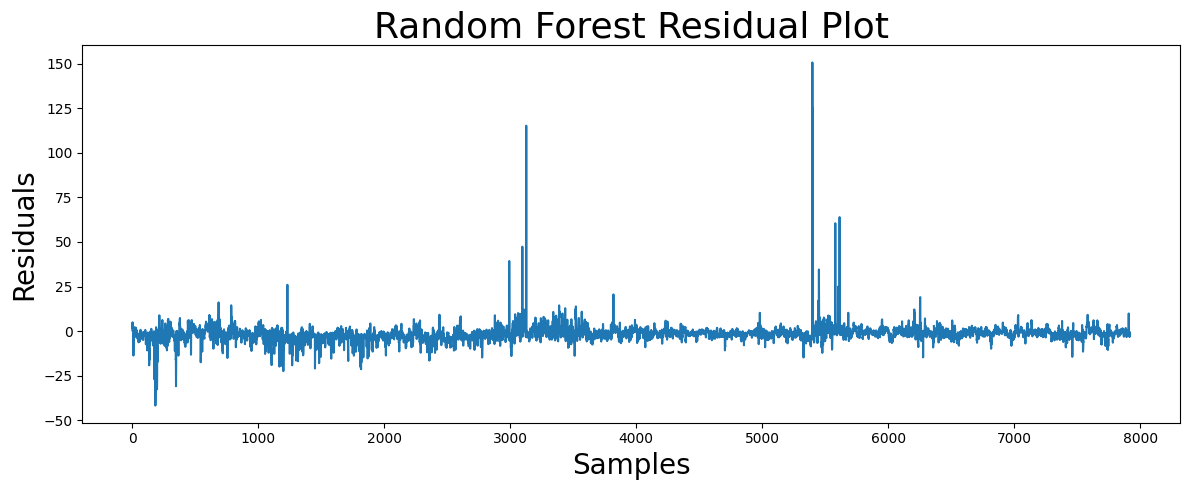

In [ ]:
residuals_rf = y_test.values - y_pred_rf

plt.figure(figsize=(12, 5))
plt.plot(residuals_rf)
plt.title("Random Forest Residual Plot", fontsize=26)
plt.xlabel("Samples", fontsize=20)
plt.ylabel("Residuals", fontsize=20)
plt.tight_layout()
plt.show()

- Error Distribution

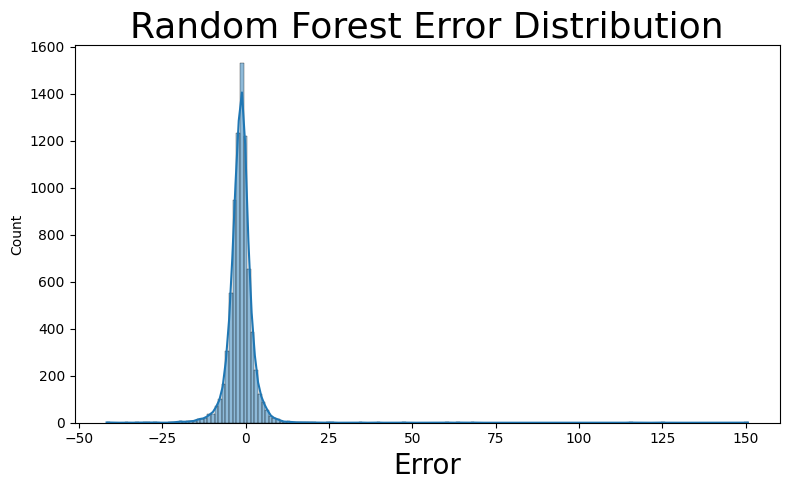

In [ ]:
## Random Forest Scatter Plot

plt.figure(figsize=(8,5))
sns.histplot(residuals_rf, kde=True)
plt.xlabel("Error", fontsize=20)
plt.title("Random Forest Error Distribution", fontsize=26)
plt.tight_layout()
plt.show()

- Actual Vs Predicted Scatter Plot

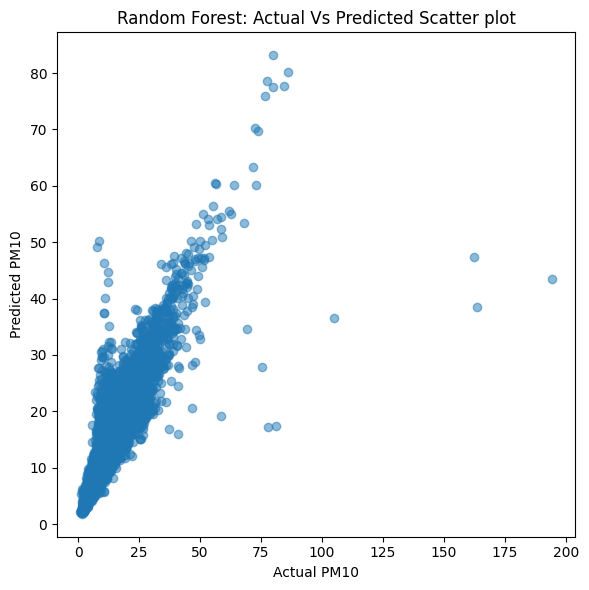

In [ ]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred_rf, alpha=0.5)
plt.xlabel("Actual PM10")
plt.ylabel("Predicted PM10")
plt.title("Random Forest: Actual Vs Predicted Scatter plot")
plt.tight_layout()
plt.show()

#### Error Distribution for both models

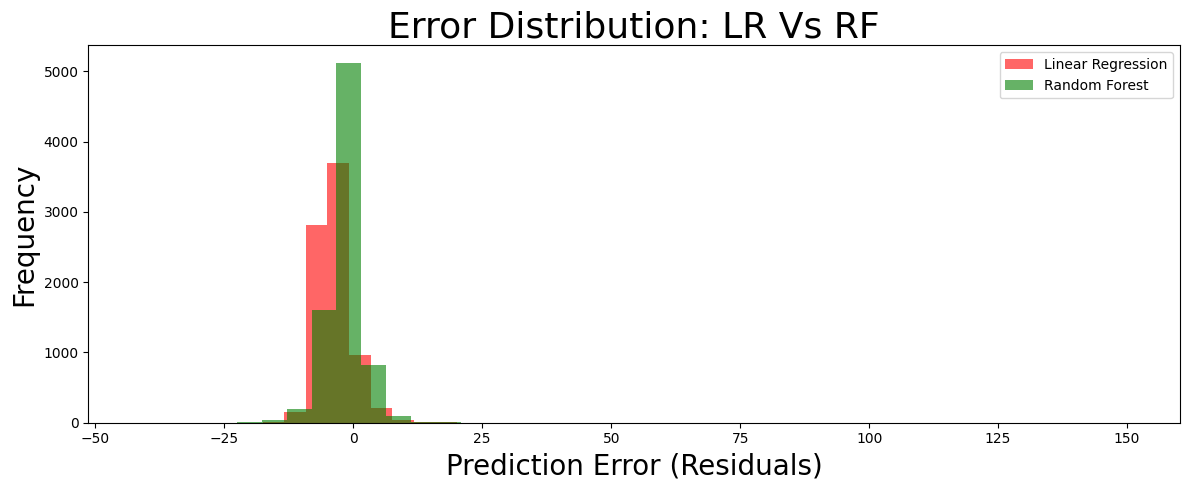

In [ ]:
plt.figure(figsize=(12, 5))
plt.hist(residuals_lr, bins=40, alpha=0.6, label="Linear Regression", color="red")
plt.hist(residuals_rf, bins=40, alpha=0.6, label="Random Forest", color="green")
plt.title("Error Distribution: LR Vs RF", fontsize=26)
plt.xlabel("Prediction Error (Residuals)", fontsize=20)
plt.ylabel("Frequency", fontsize=20)
plt.legend()
plt.tight_layout()
plt.show()

### g.3) Model Comparison

- Comparison table

In [ ]:
results = {
    "Linear Regression": {
        "R2": r2_lr,
        "RSME": rmse_lr
    },
    "Random Forest": {
        "R2": r2_rf,
        "RSME": rmse_rf
    }
}

pd.DataFrame(results).T

,R2,RSME
Linear Regression,0.572382,5.844048
Random Forest,0.708314,4.826629


- Comparison Plot

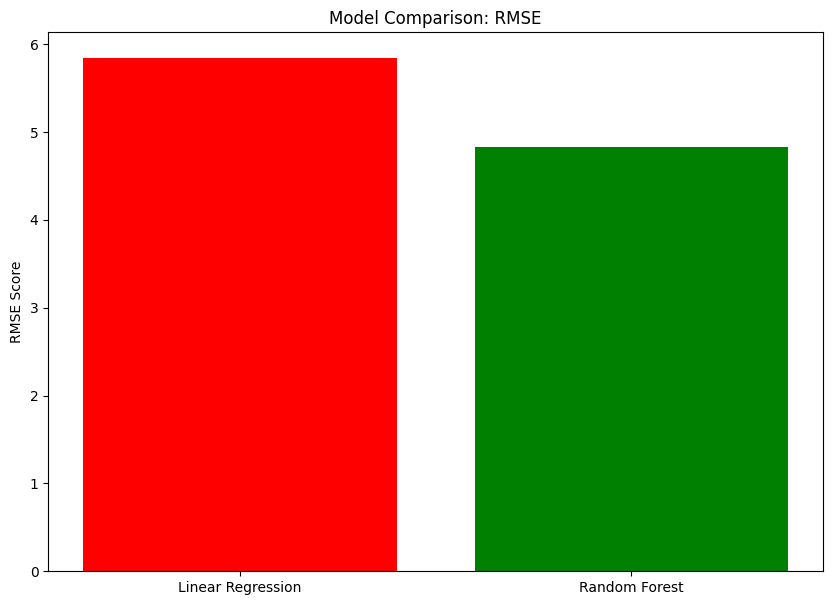

In [ ]:
plt.figure(figsize=(10, 7))
models = ["Linear Regression", "Random Forest"]
rmse_scores = [rmse_lr, rmse_rf]

plt.bar(models, rmse_scores, color=["red", "green"])
plt.ylabel("RMSE Score")
plt.title("Model Comparison: RMSE")
plt.show()

### g.4) Model Interpretation


#### Random Forest Feature Importance

- Extract and Sort Importances

In [ ]:
importances = rf_model.feature_importances_
feature_names = X_train.columns
fi_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values(by="importance", ascending=False)

fi_df

,feature,importance
4,PM2.5 particulate matter (Hourly measured),0.619054
12,PM2.5 particulate matter (Hourly measured)_roll3,0.060787
9,PM2.5 particulate matter (Hourly measured)_lag1,0.036774
14,Ozone_roll3,0.035413
7,month,0.033638
3,Ozone,0.032166
5,Sulphur dioxide,0.031449
0,Nitric oxide,0.025704
13,Nitrogen dioxide_roll3,0.020206
2,Nitrogen oxides as nitrogen dioxide,0.019757


- Plot: Feature Importance

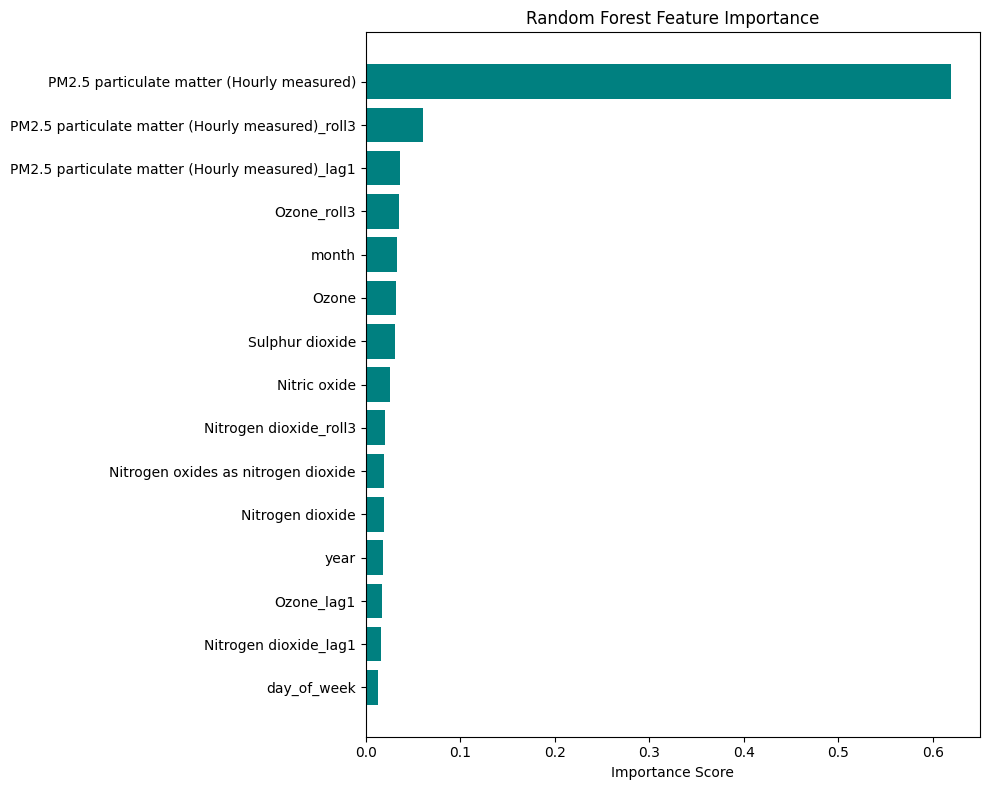

In [ ]:
plt.figure(figsize=(10,8))
plt.barh(fi_df["feature"], fi_df["importance"], color="teal")
plt.gca().invert_yaxis()
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()

#### Linear Regression Standardised Coefficients

- Standardise Features and Fit

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr_std = LinearRegression()
lr_std.fit(X_train_scaled, y_train)

coef_df = pd.DataFrame({
    "feature": X.columns,
    "coefficient": lr_std.coef_
}).sort_values(by="coefficient", ascending=False)

coef_df

,feature,coefficient
4,PM2.5 particulate matter (Hourly measured),6.007955
9,PM2.5 particulate matter (Hourly measured)_lag1,1.799711
3,Ozone,1.396836
1,Nitrogen dioxide,0.968863
6,year,0.935339
2,Nitrogen oxides as nitrogen dioxide,0.524160
13,Nitrogen dioxide_roll3,0.276596
0,Nitric oxide,0.070517
12,PM2.5 particulate matter (Hourly measured)_roll3,0.054313
10,Nitrogen dioxide_lag1,0.044522


- Plot: Standardised Coefficients

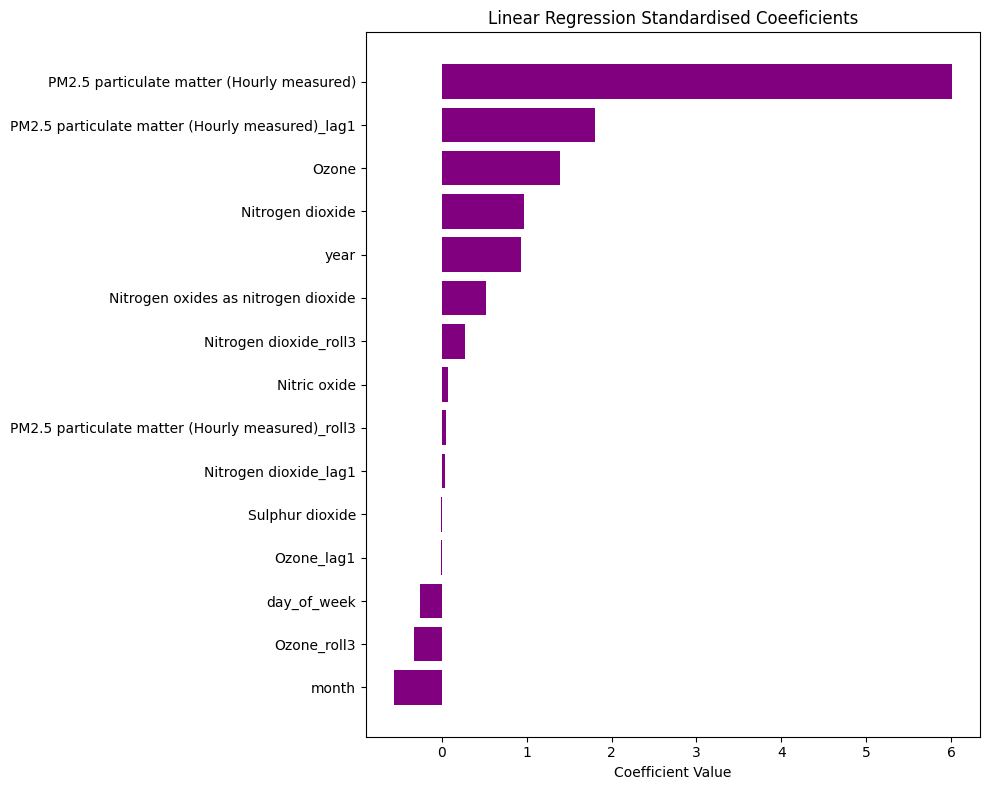

In [ ]:
plt.figure(figsize=(10, 8))
plt.barh(coef_df["feature"], coef_df["coefficient"], color="purple")
plt.gca().invert_yaxis()
plt.title("Linear Regression Standardised Coeeficients")
plt.xlabel("Coefficient Value")
plt.tight_layout()
plt.show()

### h) Forecast

- Forecasting next hour

In [ ]:
# getting last row of the cleaned dataset
last_row = df_cleaned.iloc[-1].copy()

#creating next timestamp
next_timestamp = last_row["datetime"] + timedelta(hours=1)  

#build feature for prediction
X_last = last_row.drop(labels=["PM10 particulate matter (Hourly measured)", "datetime"]).values.reshape(1, -1)

#predict using trained random forest model
next_pm10 = rf_model.predict(X_last)[0]

#Message
print("Last Timestamp:", last_row["datetime"])
print("Last Actual PM10:", last_row["PM10 particulate matter (Hourly measured)"])
print("Next Timestamp:", next_timestamp)
print("Predicted Next Hour PM10:", next_pm10)

Last Timestamp: 2023-12-23 02:00:00
Last Actual PM10: 7.275
Next Timestamp: 2023-12-23 03:00:00
Predicted Next Hour PM10: 8.854873333333337


- Forecast Plot

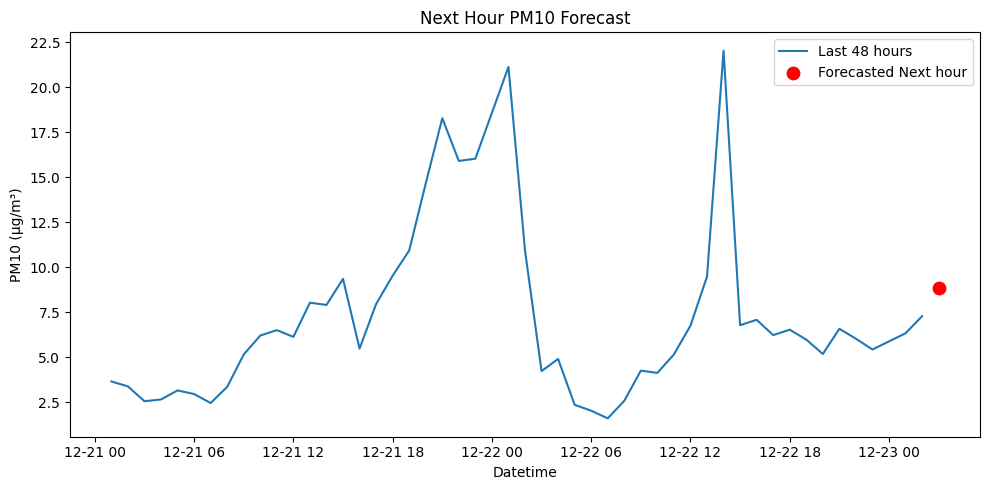

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(df_cleaned["datetime"].tail(48),
df_cleaned["PM10 particulate matter (Hourly measured)"].tail(48),
label="Last 48 hours")
plt.scatter(next_timestamp, next_pm10, color="red", label="Forecasted Next hour",  s=80)
plt.title("Next Hour PM10 Forecast")
plt.xlabel("Datetime")
plt.ylabel("PM10 (µg/m³)")
plt.legend()
plt.tight_layout()
plt.show()